# Toy notebook: Autoregressive models for state-to-state collisions in DSMC — with electronic excitation (Keras / TensorFlow)

**Goal:** An autoregressive (AR) network learns from "QCT trajectories" how the internal state $(e, v, J)$ of a molecule changes in a collision, i.e. electronic state, vibration and rotation. It thereby replaces a huge state-to-state table in the DSMC collision step.

**Outline**
1. Model system: diatomic molecule **A₂** with **three electronic states** X, A, B (each an anharmonic oscillator + rigid rotor) colliding with an atom **B**
2. "True" collision physics as a stand-in for QCT, with exactly satisfied detailed balance, including electronic quenching and excitation
3. Synthetic training data
4. AR model $p_\theta(e', v', J' \mid \mathbf c) = p_\theta(e' \mid \mathbf c)\,p_\theta(v' \mid e', \mathbf c)\,p_\theta(J' \mid e', v', \mathbf c)$ with energy masks
5. Training (maximum likelihood)
6. Validation: conditional distributions, detailed balance, **Metropolis-Hastings correction** (exact detailed balance by construction)
7. **0D DSMC heat bath, scenario 1 (heating):** hot translation, molecules in the ground state
8. **0D DSMC heat bath, scenario 2 (quenching):** electronically excited molecules in a cold gas

Units: energies in Kelvin ($k_B = 1$), masses in amu, velocities such that $E = \tfrac12 m v^2$ holds in K. Runs on the CPU in about 20 minutes.

In [7]:
import os
os.environ.setdefault("KERAS_BACKEND", "tensorflow")
os.environ.setdefault("TF_CPP_MIN_LOG_LEVEL", "3")

import time
import numpy as np
import tensorflow as tf
import keras
from keras import layers
import matplotlib.pyplot as plt

SEED = 0
rng = np.random.default_rng(SEED)
keras.utils.set_random_seed(SEED)
print("TensorFlow", tf.__version__, "| Keras", keras.__version__,
      "| GPUs:", tf.config.list_physical_devices("GPU"))

TensorFlow 2.21.0 | Keras 3.15.1 | GPUs: []


## 1. Model system: energy levels

The molecule A₂ has three electronic states X, A, B. The energy of a state $(e, v, J)$ is the sum of an electronic, a vibrational and a rotational part, and its degeneracy is the product of the electronic and rotational degeneracies:

$$
\varepsilon(e,v,J) = T_e + \big[G_e(v) - G_e(0)\big] + B_\text{rot}\,J(J+1),
\qquad g(e,J) = g_e\,(2J+1)
$$

Writing the energy as a simple sum assumes the Born-Oppenheimer separation (and neglects rotation-vibration coupling).

| State | $T_e$ [K] | $g_e$ | $\omega_e$ [K] | $\omega_e x_e$ [K] |
|---|---|---|---|---|
| X (ground state) | 0 | 1 | 3000 | 20 |
| A | 9000 | 3 | 2400 | 22 |
| B | 16000 | 2 | 2000 | 25 |

$B_\text{rot} = 8$ K for all electronic states (a simplification). With $v = 0\dots9$ and $J = 0\dots49$ the system has $3 \times 10 \times 50 = 1500$ states.

**Electronic term $T_e$:** the energy of the lowest level $(v=0, J=0)$ of electronic state $e$, measured from the ground state. X is the reference at 0 K, A lies 9000 K higher and B 16 000 K higher.

**Vibration, the anharmonic oscillator:**
$$
G_e(v) = \omega_e(v+\tfrac12) - \omega_e x_e\,(v+\tfrac12)^2
\quad\Rightarrow\quad
G_e(v) - G_e(0) = \omega_e\,v - \omega_e x_e\,v(v+1)
$$
- The first term is the harmonic oscillator: equally spaced levels $\omega_e$ apart, with zero-point energy $\tfrac12\omega_e$.
- The second term is the anharmonic correction. A real bond gets softer as it stretches, so the levels move closer together going up.
- Why subtract $G_e(0)$? The zero-point energy is already contained in the reference $T_e$. Subtracting it puts $v = 0$ exactly at $T_e$, so $T_e$ really is the energy of the lowest level of state $e$.
- Excited electronic states typically have a lower $\omega_e$ (and larger $\omega_e x_e$) because the bond is weaker.

Vibrational energies $G_e(v) - G_e(0)$ in K, relative to $T_e$:

| $v$ | X | A | B |
|---|---|---|---|
| 0 | 0 | 0 | 0 |
| 1 | 2960 | 2356 | 1950 |
| 2 | 5880 | 4668 | 3850 |
| 3 | 8760 | 6936 | 5700 |
| ⋮ | ⋮ | ⋮ | ⋮ |
| 9 | 25 200 | 19 620 | 15 750 |

**Rotation, the rigid rotor:** $B_\text{rot}\,J(J+1)$. The levels get further apart with increasing $J$: 0, 16, 48, 96, … K. For $J = 49$ the rotational energy is $8 \cdot 49 \cdot 50 = 19\,600$ K.

Adding $T_e$ gives the absolute energies. The highest state in the system is B$(v=9, J=49)$ at $16\,000 + 15\,750 + 19\,600 = 51\,350$ K.

In [8]:
NE, NV, NJ = 3, 10, 50
EL_NAMES = ["X", "A", "B"]
EL_T = np.array([0.0, 9000.0, 16000.0])      # electronic term energies [K]
EL_G = np.array([1.0, 3.0, 2.0])             # electronic degeneracy
EL_W = np.array([3000.0, 2400.0, 2000.0])    # omega_e [K]
EL_WX = np.array([20.0, 22.0, 25.0])         # omega_e x_e [K]
B_ROT = 8.0

v_idx, J_idx = np.arange(NV), np.arange(NJ)
G_v = lambda w, wx, v: w * (v + 0.5) - wx * (v + 0.5) ** 2
eps_vib = np.array([G_v(w, wx, v_idx) - G_v(w, wx, 0) for w, wx in zip(EL_W, EL_WX)])   # (NE, NV)
eps_rot = B_ROT * J_idx * (J_idx + 1)
g_rot = 2.0 * J_idx + 1

EPS = EL_T[:, None, None] + eps_vib[:, :, None] + eps_rot[None, None, :]   # (NE, NV, NJ)
NS = NE * NV * NJ
eps_flat = EPS.ravel()
g_flat = (EL_G[:, None, None] * np.ones((1, NV, 1)) * g_rot[None, None, :]).ravel()
e_of, v_of, J_of = np.unravel_index(np.arange(NS), (NE, NV, NJ))   # state i -> (e, v, J)
idx = lambda e, v, J: (e * NV + v) * NJ + J

for e in range(NE):
    print(f"{EL_NAMES[e]}: T_e = {EL_T[e]:6.0f} K, eps_vib =", np.round(eps_vib[e]).astype(int))
print("States:", NS, "| max. energy:", eps_flat.max(), "K")

X: T_e =      0 K, eps_vib = [    0  2960  5880  8760 11600 14400 17160 19880 22560 25200]
A: T_e =   9000 K, eps_vib = [    0  2356  4668  6936  9160 11340 13476 15568 17616 19620]
B: T_e =  16000 K, eps_vib = [    0  1950  3850  5700  7500  9250 10950 12600 14200 15750]
States: 1500 | max. energy: 51350.0 K


## 2. "True" collision physics (stand-in for QCT)

A real QCT run integrates classical trajectories on a potential energy surface. Here the outcome distribution $P(f \mid i, E_\text{tr})$ is instead written down in closed form, so it is known exactly and can later be compared against the network.

**a) Symmetric coupling $K_{if}$:** favours small jumps in each quantum number:

$$
K_{if} \propto \exp\!\Big(-\frac{|\Delta e|}{a_e} - \frac{|\Delta J|}{a_J} - \frac{|\Delta v|}{a_v(\Delta e)}\Big),
\qquad a_v(\Delta e) = \begin{cases} a_v & \Delta e = 0 \\ a_v^\text{el} > a_v & \Delta e \neq 0\end{cases}
$$

| Constant | Value | Effect |
|---|---|---|
| $a_J$ | 10 | large $\Delta J$ jumps are common, so rotation relaxes fast ($\tau_\text{rot} \approx 6$ collisions) |
| $a_v$ | 0.3 | vibration is stiff, $\Delta v$ is mostly 0 or ±1 |
| $a_e$ | 0.2 | electronic transitions are rare |
| $a_v^\text{el}$ | 2 | if $e$ changes, $v$ may jump strongly |

This reproduces the **hierarchy of time scales** of real molecules: rotation relaxes within a few collisions, vibration and electronic excitation within tens to hundreds. For real N₂, $Z_\text{vib}$ is larger by orders of magnitude. Here it is compressed to keep the runtime short. The large $a_v^\text{el}$ means that in **quenching** part of the electronic energy goes directly into ground-state vibration (E-V transfer), not only into translation (E-T). This is a rough analogue of Franck-Condon effects.

The diagonal of $K$ is set to 0, and $K$ is scaled so that every row sums to at most 1. This keeps the elastic remainder $P(i \mid i)$ non-negative.

**b) Energy conservation and acceptance:** the total energy $E_\text{tot} = E_{\text{tr},i} + \varepsilon_i$ is conserved, so $E_{\text{tr},f} = E_\text{tot} - \varepsilon_f$. Channels with $E_{\text{tr},f} \le 0$ are closed. Open channels are weighted with the Metropolis factor $\min\!\big(1, \tfrac{g_f E_{\text{tr},f}}{g_i E_{\text{tr},i}}\big)$.

**c) Overall inelasticity** $s(E_\text{tot}) = 1 - e^{-E_\text{tot}/E_0}$ with $E_0 = 3000$ K: at low total energy, most collisions are elastic.

Together:

$$
P(f \mid i) = s(E_\text{tot})\,K_{if}\,\min\!\Big(1, \frac{g_f E_{\text{tr},f}}{g_i E_{\text{tr},i}}\Big) \quad (f \neq i),
\qquad P(i \mid i) = 1 - \sum_{f \neq i} P(f \mid i)
$$

**Detailed balance holds exactly.** Multiplying by $g_i E_{\text{tr},i}$ gives $s\,K_{if}\,\min(g_i E_{\text{tr},i},\, g_f E_{\text{tr},f})$, and every factor is symmetric in $i \leftrightarrow f$ ($s$ depends only on the conserved $E_\text{tot}$). Hence

$$
g_i\,E_{\text{tr},i}\;P(f \mid i) \;=\; g_f\,E_{\text{tr},f}\;P(i \mid f).
$$

The code below checks this numerically on 2000 random state pairs, and prints the electronic branching ratios for a collision of A$(v=0, J=0)$ at $E_\text{tr} = 2000$ K.

In [ ]:
A_V, A_J, A_E, A_V_EL, E0 = 0.3, 10.0, 0.2, 2.0, 3000.0

de = np.abs(e_of[:, None] - e_of[None, :])
dv = np.abs(v_of[:, None] - v_of[None, :])
dJ = np.abs(J_of[:, None] - J_of[None, :])
K = np.exp(-de / A_E - dJ / A_J - dv / np.where(de > 0, A_V_EL, A_V))
np.fill_diagonal(K, 0.0)
K /= K.sum(1).max()                    # row sums <= 1  -> P(i|i) >= 0
del de, dv, dJ

def true_transition_probs(i, Etr):
    # Exact transition probabilities P(f | i, E_tr), shape (N, NS)
    Etot = Etr + eps_flat[i]
    Etr_f = Etot[:, None] - eps_flat[None, :]
    ratio = g_flat[None, :] * np.clip(Etr_f, 0, None) / (g_flat[i] * Etr)[:, None]
    acc = np.where(Etr_f > 0, np.minimum(1.0, ratio), 0.0)
    s = 1.0 - np.exp(-Etot / E0)
    P = s[:, None] * K[i] * acc
    P[np.arange(len(i)), i] = 0.0
    P[np.arange(len(i)), i] = 1.0 - P.sum(1)
    return P

def sample_categorical_np(P, rng):
    c = np.cumsum(P, axis=1) # cumulative sum of probabilities
    u = rng.random(len(P))[:, None] * c[:, -1:] # random uniform numbers scaled by the last cumulative sum
    return (u > c).sum(1) # number of categories where u > c, which gives the sampled index

def true_sampler(i, Etr, rng=rng):
    return sample_categorical_np(true_transition_probs(i, Etr), rng)

# Test detailed balance of the reference
i_t = rng.integers(0, NS, 2000); f_t = rng.integers(0, NS, 2000)
Etot_t = np.maximum(eps_flat[i_t], eps_flat[f_t]) + rng.uniform(100, 20000, 2000)
Pif = true_transition_probs(i_t, Etot_t - eps_flat[i_t])[np.arange(2000), f_t]
Pfi = true_transition_probs(f_t, Etot_t - eps_flat[f_t])[np.arange(2000), i_t]
lhs = g_flat[i_t] * (Etot_t - eps_flat[i_t]) * Pif
rhs = g_flat[f_t] * (Etot_t - eps_flat[f_t]) * Pfi
m = (lhs > 0) & (i_t != f_t)
print("max. relative deviation from detailed balance:", np.max(np.abs(lhs[m] / rhs[m] - 1)))

# How likely is quenching A(0,0) -> X at E_tr = 2000 K?
P = true_transition_probs(np.array([idx(1, 0, 0)]), np.array([2000.0]))[0].reshape(NE, NV, NJ)
print("P(e' | A(v=0,J=0), E_tr=2000 K):", np.round(P.sum((1, 2)), 4))
print("  of which vibrational distribution in X:", np.round(P[0].sum(1) / P[0].sum(), 3))

max. relative deviation from detailed balance: 2.220446049250313e-16
P(e' | A(v=0,J=0), E_tr=2000 K): [0.0072 0.9928 0.    ]
  of which vibrational distribution in X: [0.474 0.283 0.162 0.081 0.    0.    0.    0.    0.    0.   ]


## 3. Synthetic "QCT" data

Each row is one trajectory $(i, E_\text{tr}) \to f$. $N = 10^6$ rows are generated in batches of 10 000. For each row:

1. **Initial internal state $i$**
   - **60 %:** draw $T_\text{int} \sim U[200, 15000]$ K, then sample $i$ from the Boltzmann distribution $\propto g_i\,e^{-\varepsilon_i / T_\text{int}}$.
   - **40 %:** draw $i$ uniformly from **all** 1500 states. This adds strongly non-thermal states such as "electronically excited but rotationally cold". The quenching scenario needs them. A network that has only seen Boltzmann initial states would have to extrapolate there.
2. **Translational energy:** draw $T_\text{tr} \sim U[500, 15000]$ K, then $E_\text{tr} \sim \text{Gamma}(2, T_\text{tr})$. The density $\propto E\,e^{-E/T_\text{tr}}$ is the collision-rate-weighted distribution of relative energy in a thermal gas, i.e. the energies at which collisions actually happen. $T_\text{tr}$ is drawn independently of $T_\text{int}$, so the data also covers non-equilibrium combinations such as hot translation with cold internal modes.
3. **Final state $f$:** sample from the exact $P(\cdot \mid i, E_\text{tr})$ of section 2 by inverse-CDF sampling.

The network only ever sees these samples, exactly as it would with real QCT data. Because the true $P$ is known in closed form, the learned conditionals and detailed balance can later be checked against the exact answer. The printed fractions of elastic collisions, $\Delta v \neq 0$ and $\Delta e \neq 0$ show the rotation → vibration → electronic hierarchy directly in the data.

In [10]:
def boltzmann_states(T, rng):
    w = g_flat[None, :] * np.exp(-eps_flat[None, :] / T[:, None])
    return sample_categorical_np(w, rng)

def make_dataset(n, rng, batch=10000, frac_uniform=0.4):
    I, E, Fs = [], [], []
    for k in range(0, n, batch):
        b = min(batch, n - k)
        # 1. All initial states sampled from Boltzmann distribution at random temperatures
        i = boltzmann_states(rng.uniform(200, 15000, b), rng)
        # 2. Overwrite a fraction of initial states with uniform sampling
        uni = rng.random(b) < frac_uniform
        i[uni] = rng.integers(0, NS, uni.sum()) # initial states sampled uniformly from all possible states (NS)
        # 3. Sample translational energies
        Etr = rng.gamma(2.0, rng.uniform(500, 15000, b)) # translational energies sampled from a gamma distribution
        # 4. Sample final states from the true transition probabilities
        f = true_sampler(i, Etr, rng)
        # 5. Append to dataset
        I.append(i); E.append(Etr); Fs.append(f)
    return np.concatenate(I), np.concatenate(E), np.concatenate(Fs)

t0 = time.time()
N_DATA = 1_000_000
I_all, E_all, F_all = make_dataset(N_DATA, rng) # Initial states, translational energies, final states
print(f"{N_DATA} trajectories in {time.time()-t0:.1f}s")
print(f"Fraction elastic: {(I_all == F_all).mean():.3f} | with Δv≠0: {(v_of[I_all] != v_of[F_all]).mean():.3f} "
      f"| with Δe≠0: {(e_of[I_all] != e_of[F_all]).mean():.4f}")

1000000 trajectories in 83.3s
Fraction elastic: 0.349 | with Δv≠0: 0.045 | with Δe≠0: 0.0129


### What the training data looks like

The training data is a simple table with $10^6$ rows. Each row is **one single collision**:

| $e$ | $v$ | $J$ | $E_\text{tr}$ [K] | → | $e'$ | $v'$ | $J'$ |
|---|---|---|---|---|---|---|---|
| X | 1 | 17 | 2371 | → | X | 1 | 13 |
| X | 6 | 42 | 3778 | → | X | 6 | 19 |
| B | 4 | 21 | 17451 | → | B | 4 | 21 |
| … | | | | | | | |

The first four columns are the **condition** $\mathbf c$, i.e. what is known before the collision. The last three are the **outcome** $f$. $E_\text{tr}'$ follows from energy conservation and is not part of the data. In the code these are the arrays `I_all` (state index $i$), `E_all` ($E_\text{tr}$) and `F_all` (state index $f$).

The network only ever sees samples $(i, E_\text{tr}, f)$, exactly as it would with real QCT data. Because the true $P$ is known in closed form, the later steps can compare the learned conditionals and the detailed-balance check against the exact answer. The script also prints the fraction of rows that are elastic, that have $\Delta v \ne 0$, and that have $\Delta e \ne 0$, which shows the rotation, then vibration, then electronic hierarchy directly in the data.

The crucial point: **the outcome is random.** The same initial state can end up in a different final state in every collision. Behind every condition there is a probability table $P(f \mid \mathbf c)$ over all 1500 final states. This table is **not** in the data. The data only contains what was "rolled" once. It is like a loaded die: you see the throws, never the probabilities.

## 4. The autoregressive model

Three heads in **coarse → fine** order:

$$
p_\theta(e', v', J' \mid \mathbf c) =
\text{Softmax}\big(\ell_e(\mathbf c) + M_e\big)_{e'}\cdot
\text{Softmax}\big(\ell_v(\mathbf c, e') + M_v(e')\big)_{v'}\cdot
\text{Softmax}\big(\ell_J(\mathbf c, e', v') + M_J(e', v')\big)_{J'}
$$

- Condition $\mathbf c$: one-hot($e$), one-hot($v$), one-hot($J$), $\log E_\text{tr}$, $E_\text{tot}$
- **Energy masks:** $T_{e'} < E_\text{tot}$, then $T_{e'} + \varepsilon_\text{vib}^{e'}(v') < E_\text{tot}$, then $\varepsilon(e', v', J') < E_\text{tot}$. The ground state $(X, 0, 0)$ is always allowed, so every head has at least one valid choice.
- Because the $v'$ head knows $e'$, it can learn a different vibrational ladder for each electronic state.
- $E_\text{tr}' = E_\text{tot} - \varepsilon(e', v', J')$ is **computed**, not learned. Energy conservation is exact.

The electronic quantum number comes first because it fixes the largest part of the available energy.

The probability to be in X after the collision, is the sum over all post state in X:

$$
p(e´ = X | c ) = \sum_{(v´,J´) < E_{tot}} p(X, v´, J´ | c)
$$

Therefore, the probability to land in X is not only the amount of possible X(v´, J´) states, but also the probability to land in this state

### What the model learns

The model has to reconstruct the hidden table $P(f \mid \mathbf c)$, for **every** condition $\mathbf c$, including conditions that never occurred in exactly this form in the data. It does so in three steps, the same way one would roll a final state by hand:

```
condition c = (e, v, J, E_tr)
     │
     ▼
 net_e:  "which electronic state?"         → p(e' | c)            3 numbers
     │  (e' is passed on)
     ▼
 net_v:  "which v', given this e'?"        → p(v' | e', c)        3 × 10 numbers
     │  (e' and v' are passed on)
     ▼
 net_J:  "which J', given e' and v'?"      → p(J' | e', v', c)    3 × 10 × 50 numbers
```

Multiplying the three steps gives $p(e')\,p(v' \mid e')\,p(J' \mid e', v')$, i.e. $3 \times 10 \times 50 = 1500$ numbers, **one per final state**. This is the **full** joint table, without any independence assumption. A model without coupling, $p(e')\,p(v')\,p(J')$, would have only $3 + 10 + 50 = 63$ numbers. It could not express, for example, that "quenched to X" goes together with "high $v'$".

In [11]:
EPS_T = tf.constant(EPS, tf.float32)                                  # (NE, NV, NJ)
EVIB_ABS_T = tf.constant(EL_T[:, None] + eps_vib, tf.float32)         # (NE, NV)
EL_T_T = tf.constant(EL_T, tf.float32)                                # (NE,)
EFLAT_T = tf.constant(eps_flat, tf.float32)                           # (NS,)
NEG = -1e9                                                            # "minus infinity"

def mlp(din, dout, h, depth=3, name=None):
    return keras.Sequential(
        [keras.Input((din,))]
        + [layers.Dense(h, activation="silu") for _ in range(depth)]
        + [layers.Dense(dout)],
        name=name)

class ARCollisionModel(keras.Model):
    # p(e', v', J' | c) = p(e' | c) p(v' | e', c) p(J' | e', v', c)  with energy masks

    def __init__(self, h=256, **kw):
        super().__init__(**kw)
        din = NE + NV + NJ + 2
        self.net_e = mlp(din, NE, h, name="net_e")
        self.net_v = mlp(din + NE, NV, h, name="net_v")
        self.net_J = mlp(din + NE + NV, NJ, h, name="net_J")

    @staticmethod
    def split(i):
        return i // (NV * NJ), (i // NJ) % NV, i % NJ

    def features(self, i, Etr):
        i = tf.cast(i, tf.int32); Etr = tf.cast(Etr, tf.float32)
        e, v, J = self.split(i)
        Etot = Etr + tf.gather(EFLAT_T, i) # translational energy + internal energy of state i (Eel + Evib + Erot)
        x = tf.concat([tf.one_hot(e, NE), tf.one_hot(v, NV), tf.one_hot(J, NJ),
                       tf.math.log(Etr / 1000.0)[:, None], (Etot / 10000.0)[:, None]], axis=1)
        return x, Etot

    def logits_e(self, x, Etot):
        return tf.where(EL_T_T[None, :] >= Etot[:, None], NEG, self.net_e(x))

    def logits_v(self, x, Etot, e2):
        l = self.net_v(tf.concat([x, tf.one_hot(e2, NE)], axis=1))
        return tf.where(tf.gather(EVIB_ABS_T, e2) >= Etot[:, None], NEG, l)

    def logits_J(self, x, Etot, e2, v2):
        l = self.net_J(tf.concat([x, tf.one_hot(e2, NE), tf.one_hot(v2, NV)], axis=1))
        lev = tf.gather_nd(EPS_T, tf.stack([e2, v2], axis=1))           # (N, NJ)
        return tf.where(lev >= Etot[:, None], NEG, l)

    def log_prob(self, i, Etr, f):
        x, Etot = self.features(i, Etr)
        e2, v2, J2 = self.split(tf.cast(f, tf.int32))
        lp_e = tf.gather(tf.nn.log_softmax(self.logits_e(x, Etot)), e2, batch_dims=1)
        lp_v = tf.gather(tf.nn.log_softmax(self.logits_v(x, Etot, e2)), v2, batch_dims=1)
        lp_J = tf.gather(tf.nn.log_softmax(self.logits_J(x, Etot, e2, v2)), J2, batch_dims=1)
        return lp_e + lp_v + lp_J

    def call(self, inputs):
        # Keras interface: inputs = (i, E_tr, f)  ->  log p(f | i, E_tr)
        i, Etr, f = inputs
        return self.log_prob(i, Etr, f)

    def full_probs(self, i, Etr):
        # Exact model distribution over all NS final states, shape (N, NS), order (e, v, J)
        x, Etot = self.features(i, Etr)
        pe = tf.nn.softmax(self.logits_e(x, Etot))
        out = []
        for e2 in range(NE):
            ee = tf.fill(tf.shape(Etot), e2)
            pv = tf.nn.softmax(self.logits_v(x, Etot, ee))
            for v2 in range(NV):
                vv = tf.fill(tf.shape(Etot), v2)
                pJ = tf.nn.softmax(self.logits_J(x, Etot, ee, vv))
                out.append(pe[:, e2:e2+1] * pv[:, v2:v2+1] * pJ)
        return tf.concat(out, axis=1)

    @tf.function(reduce_retracing=True)
    def sample(self, i, Etr):
        x, Etot = self.features(i, Etr)
        e2 = tf.random.categorical(self.logits_e(x, Etot), 1, dtype=tf.int32)[:, 0]
        v2 = tf.random.categorical(self.logits_v(x, Etot, e2), 1, dtype=tf.int32)[:, 0]
        J2 = tf.random.categorical(self.logits_J(x, Etot, e2, v2), 1, dtype=tf.int32)[:, 0]
        return (e2 * NV + v2) * NJ + J2

model = ARCollisionModel()
_ = model((I_all[:2], E_all[:2], F_all[:2]))     # builds the weights
model.summary()
print("A table would need NS*NS*N_E ≈", f"{NS*NS*100:.1e} entries with 100 energy grid points")

Model: "ar_collision_model"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ net_e (Sequential)              │ (None, 3)              │       149,251 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ net_v (Sequential)              │ (None, 10)             │       151,818 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ net_J (Sequential)              │ (None, 50)             │       164,658 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 465,727 (1.78 MB)

 Trainable params: 465,727 (1.78 MB)

 Non-trainable params: 0 (0.00 B)

A table would need NS*NS*N_E ≈ 2.2e+08 entries with 100 energy grid points


## 5. Training (maximum likelihood / teacher forcing)

$\mathcal L = -\frac1N \sum \log p_\theta(f \mid i, E_\text{tr})$. All three factors are evaluated in parallel because $e'$ and $v'$ are known from the data.

Keras trick: `call` returns $\log p_\theta$ directly. The loss is `-y_pred`, and `y_true` is a dummy. This way plain `model.fit` works.

**A single training step, concretely.** For the row `X(v=1, J=17), E_tr = 2371 K → X(v=1, J=13)` the loss is

$$
\mathcal L = -\Big[\log p_\theta(e'{=}X \mid \mathbf c) + \log p_\theta(v'{=}1 \mid X, \mathbf c) + \log p_\theta(J'{=}13 \mid X, 1, \mathbf c)\Big]
$$

The gradient pushes these three probabilities up a little. The true $e'$ and $v'$ from the data are fed into the later heads ("teacher forcing"), so each head is an ordinary classifier. After $10^6$ rows the probabilities have settled at the **frequencies** with which the outcomes occur. In principle the network is keeping a tally. The advantage over a real tally sheet is that it interpolates between similar conditions and needs no table with more than $10^8$ entries.

### Understanding the loss

**The basic problem.** The model predicts *probabilities* ("0.7 % quenching, 99.3 % no quenching"), but the data never contain probabilities, only *single outcomes*: this trajectory ended in X, the next one in A. A probabilistic prediction is therefore scored by asking: **how much probability did the model give to what actually happened?**

**The penalty $-\log p$.** Each training row adds $-\log p$, where $p$ is the probability the model assigned to the observed outcome:

| Model gave the observed outcome | Penalty $-\log p$ |
|---|---|
| 1.0 (certain, and right) | 0 |
| 0.7 | 0.36 |
| 0.5 | 0.69 |
| 0.1 | 2.3 |
| 0.01 | 4.6 |
| 0 (impossible, yet it happened) | ∞ |

Small penalty if the outcome was expected, large if the model was surprised, infinite if it called something impossible that then happened. The loss is the **mean penalty** over all rows.

**Example: a weather forecaster.** It rains on 70 % of days. A forecaster announces the same rain probability $q$ every day. On rainy days he gets $-\log q$, on dry days $-\log(1-q)$:

| Forecast $q$ | Mean penalty |
|---|---|
| 0.5 | 0.69 |
| 0.6 | 0.63 |
| **0.7 (the truth)** | **0.61** ← minimum |
| 0.8 | 0.64 |
| 0.9 | 0.76 |
| 1.0 | ∞ |

1. **The minimum is exactly at the true frequency.** Overconfidence is punished on dry days, underconfidence on rainy days. Honest probabilities pay off. This is why the network learns frequencies.
2. **The minimum is not 0.** Even a perfect forecaster collects 0.61, because the weather is random. This unavoidable floor is the **entropy**.

**Why the optimum is the frequency (gradient view).** For softmax with this loss the gradient with respect to a logit is $\partial \ell / \partial l_k = p_k - y_k$ ($y_k = 1$ for the observed outcome, else 0). If a fraction $q$ of rows with similar conditions ends in X, the averaged gradient for the X logit is $q(p_X - 1) + (1-q)\,p_X = p_X - q$. Training only comes to rest at $p_X = q$. Masked states get zero gradient, because their logit is fixed at $-10^9$.

**Applied to the model.** The probability of a full outcome is the product of the three heads, so the penalty is the sum of three penalties:

$$
-\log\big(p(e')\,p(v' \mid e')\,p(J' \mid e', v')\big) = -\log p(e') - \log p(v' \mid e') - \log p(J' \mid e', v')
$$

Example of a rare outcome, quenching to X(2, 11) (illustrative values):

| | Probability | Penalty |
|---|---|---|
| $e' = X$ | 0.007 | 4.96 |
| $v' = 2 \mid X$ | 0.2 | 1.61 |
| $J' = 11 \mid X, 2$ | 0.05 | 3.00 |
| **total** | $7 \cdot 10^{-5}$ | **9.6** |

The penalty is high because the model expected this outcome to be rare, which is fine as long as it really is rare. Common outcomes (staying in A with a small change in $J$) get penalties around 2, and since most collisions are of this kind, the mean is much lower.

**Reading the numbers.** Validation loss ≈ 3.017, true entropy ≈ 3.016.
- **3.016** is the intrinsic randomness of the collisions. Even the exact physics cannot do better.
- **The gap of ~0.001** is the actual model error, the mean KL divergence $\mathbb E[\mathrm{KL}(P_\text{true}\,\|\,p_\theta)]$.
- **Intuition:** $e^{3.0} \approx 20$. On average a collision is about as unpredictable as picking among ~20 equally likely outcomes. Of the 1500 states, only a few dozen are serious candidates.

**Why not a simpler loss?**
- **Accuracy** ("did the most likely outcome occur?") would teach the network to always predict the most common outcome, usually "elastic". The distribution, which is exactly what DSMC needs, would be lost.
- **Squared error on the probabilities** (Brier score) would also work in principle. The log loss penalises "called impossible, but it happened" infinitely, which matters for rare channels. It is also exactly the log-likelihood that the detailed-balance check and the Metropolis-Hastings step need.

**In short:** for every trajectory the loss asks how surprised the model was by what actually happened. Training minimises the mean surprise, and the model does that best by predicting the true probabilities.

true conditional entropy (lower bound for the expected val_loss): 3.0159
Epoch 1/15
232/232 - 33s - 143ms/step - loss: 3.9275 - val_loss: 3.0868
Epoch 2/15
232/232 - 28s - 122ms/step - loss: 3.0858 - val_loss: 3.0687
Epoch 3/15
232/232 - 28s - 122ms/step - loss: 3.0648 - val_loss: 3.0459
Epoch 4/15
232/232 - 30s - 128ms/step - loss: 3.0494 - val_loss: 3.0395
Epoch 5/15
232/232 - 30s - 131ms/step - loss: 3.0459 - val_loss: 3.0366
Epoch 6/15
232/232 - 28s - 120ms/step - loss: 3.0434 - val_loss: 3.0344
Epoch 7/15
232/232 - 28s - 122ms/step - loss: 3.0410 - val_loss: 3.0328
Epoch 8/15
232/232 - 28s - 120ms/step - loss: 3.0375 - val_loss: 3.0297
Epoch 9/15
232/232 - 29s - 126ms/step - loss: 3.0333 - val_loss: 3.0261
Epoch 10/15
232/232 - 28s - 122ms/step - loss: 3.0300 - val_loss: 3.0235
Epoch 11/15
232/232 - 28s - 120ms/step - loss: 3.0272 - val_loss: 3.0218
Epoch 12/15
232/232 - 28s - 123ms/step - loss: 3.0249 - val_loss: 3.0202
Epoch 13/15
232/232 - 28s - 122ms/step - loss: 3.0228 - val_

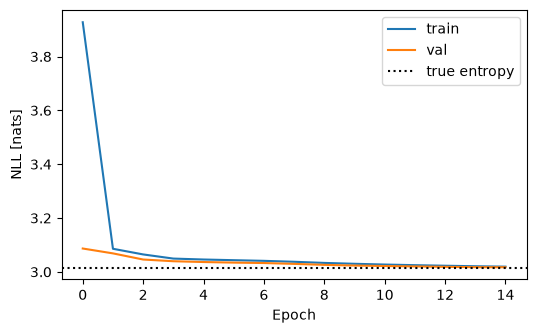

In [12]:
def nll_loss(y_true, y_pred):          # y_pred = log p_theta
    return -y_pred

n_val = 50_000
perm = rng.permutation(N_DATA)
tr, va = perm[n_val:], perm[:n_val]
X_tr = (I_all[tr].astype(np.int32), E_all[tr].astype(np.float32), F_all[tr].astype(np.int32))
X_va = (I_all[va].astype(np.int32), E_all[va].astype(np.float32), F_all[va].astype(np.int32))

EPOCHS, BS = 15, 4096
steps = EPOCHS * int(np.ceil(len(tr) / BS))
lr = keras.optimizers.schedules.CosineDecay(1e-4, decay_steps=steps, warmup_target=3e-3,
                                            warmup_steps=steps // 10)
model.compile(optimizer=keras.optimizers.AdamW(lr, weight_decay=1e-5), loss=nll_loss)

# Lower bound: entropy of the true distribution on the validation data
H_true = 0.0
for k in range(0, n_val, 10000):
    Pv = true_transition_probs(I_all[va[k:k+10000]], E_all[va[k:k+10000]])
    H_true += -(Pv * np.log(np.clip(Pv, 1e-300, None))).sum()
H_true /= n_val
print(f"true conditional entropy (lower bound for the expected val_loss): {H_true:.4f}")

t0 = time.time()
history = model.fit(X_tr, np.zeros(len(tr), np.float32), batch_size=BS, epochs=EPOCHS,
                    validation_data=(X_va, np.zeros(len(va), np.float32)), shuffle=True, verbose=2)
print(f"Training: {time.time()-t0:.0f}s  |  val NLL = {history.history['val_loss'][-1]:.4f}  vs. H_true = {H_true:.4f}")

plt.figure(figsize=(6, 3.5))
plt.plot(history.history["loss"], label="train"); plt.plot(history.history["val_loss"], label="val")
plt.axhline(H_true, color="k", ls=":", label="true entropy")
plt.xlabel("Epoch"); plt.ylabel("NLL [nats]"); plt.legend(); plt.show()

In [13]:
# One collision, step by step through the AR chain  p(e'|c) p(v'|e',c) p(J'|e',v',c)
i0  = np.array([idx(1, 0, 0)], np.int32)        # initial state: A(v=0, J=0)
Etr = np.array([2000.0], np.float32)            # relative translational energy [K]

x, Etot = model.features(i0, Etr)               # x = conditioning vector c, Etot = E_tr + eps(i)
E = Etot.numpy()[0]
print(f"E_tot = {E:.0f} K | c has shape {tuple(x.shape)} = one-hot(e,v,J) + log(E_tr/1000) + E_tot/1e4")

# Step 1: electronic state  p(e' | c)
le = model.logits_e(x, Etot)                    # (1, NE); closed channels (T_e >= E_tot) -> -1e9
pe = tf.nn.softmax(le)[0].numpy()
print("\nStep 1: p(e' | c)")
for e in range(NE):
    print(f"  {EL_NAMES[e]}: T_e={EL_T[e]:6.0f} K  logit={le[0, e].numpy():10.3g}  p={pe[e]:.4f}"
          f"  {'open' if EL_T[e] < E else 'CLOSED'}")
e2 = tf.random.categorical(le, 1, dtype=tf.int32)[:, 0]
print("  -> sampled e' =", EL_NAMES[int(e2[0])])

# Step 2: vibration  p(v' | e', c), the net gets one-hot(e') as extra input
lv = model.logits_v(x, Etot, e2)                # (1, NV); masks levels with T_e' + G(v') >= E_tot
pv = tf.nn.softmax(lv)[0].numpy()
n_open_v = int((EVIB_ABS_T.numpy()[int(e2[0])] < E).sum())
print(f"\nStep 2: p(v' | e'={EL_NAMES[int(e2[0])]}, c), {n_open_v} of {NV} levels open")
print("  p(v') =", np.round(pv, 4))
v2 = tf.random.categorical(lv, 1, dtype=tf.int32)[:, 0]
print("  -> sampled v' =", int(v2[0]))

# Step 3: rotation  p(J' | e', v', c), the net gets one-hot(e') and one-hot(v')
lJ = model.logits_J(x, Etot, e2, v2)            # (1, NJ); masks eps(e',v',J') >= E_tot
pJ = tf.nn.softmax(lJ)[0].numpy()
n_open_J = int((EPS[int(e2[0]), int(v2[0])] < E).sum())
print(f"\nStep 3: p(J' | e', v'={int(v2[0])}, c), {n_open_J} of {NJ} levels open")
print("  most probable J':", np.argsort(pJ)[::-1][:5], "with p =", np.round(np.sort(pJ)[::-1][:5], 4))
J2 = tf.random.categorical(lJ, 1, dtype=tf.int32)[:, 0]
print("  -> sampled J' =", int(J2[0]))

# Combine into the flat final state and check that log_prob is the sum of the three factors
f = (e2 * NV + v2) * NJ + J2
lp_sum = np.log(pe[int(e2[0])]) + np.log(pv[int(v2[0])]) + np.log(pJ[int(J2[0])])
print(f"\nfinal state f = {EL_NAMES[int(e2[0])]}(v={int(v2[0])}, J={int(J2[0])}), "
      f"eps_f = {eps_flat[int(f[0])]:.0f} K, E_tr' = {E - eps_flat[int(f[0])]:.0f} K")
print(f"log p (sum of factors) = {lp_sum:.4f}   model.log_prob = {model.log_prob(i0, Etr, f).numpy()[0]:.4f}")

# Compare with the true distribution
P_true = true_transition_probs(i0.astype(int), Etr.astype(float))[0].reshape(NE, NV, NJ)
print("\ntrue  P(e') =", np.round(P_true.sum((1, 2)), 4))
print("model P(e') =", np.round(pe, 4))


E_tot = 11000 K | c has shape (1, 65) = one-hot(e,v,J) + log(E_tr/1000) + E_tot/1e4

Step 1: p(e' | c)
  X: T_e=     0 K  logit=    0.0464  p=0.0112  open
  A: T_e=  9000 K  logit=      4.53  p=0.9888  open
  B: T_e= 16000 K  logit=    -1e+09  p=0.0000  CLOSED
  -> sampled e' = A

Step 2: p(v' | e'=A, c), 1 of 10 levels open
  p(v') = [1. 0. 0. 0. 0. 0. 0. 0. 0. 0.]
  -> sampled v' = 0

Step 3: p(J' | e', v'=0, c), 16 of 50 levels open
  most probable J': [0 1 2 4 3] with p = [0.6558 0.039  0.0384 0.0342 0.0333]
  -> sampled J' = 0

final state f = A(v=0, J=0), eps_f = 9000 K, E_tr' = 2000 K
log p (sum of factors) = -0.4332   model.log_prob = -0.4332

true  P(e') = [0.0072 0.9928 0.    ]
model P(e') = [0.0112 0.9888 0.    ]


The difference between `val_loss` and the true entropy is the mean KL divergence $\mathbb E\,[\mathrm{KL}(P_\text{true}\,\|\,p_\theta)]$.

## 6a. Validation: conditional distributions

Four cases, including **quenching** $A(0,0) \to ?$ and a collision from the B state. Shown are the marginal distributions of $e'$, $v'$ (summed over $e'$) and $J'$.

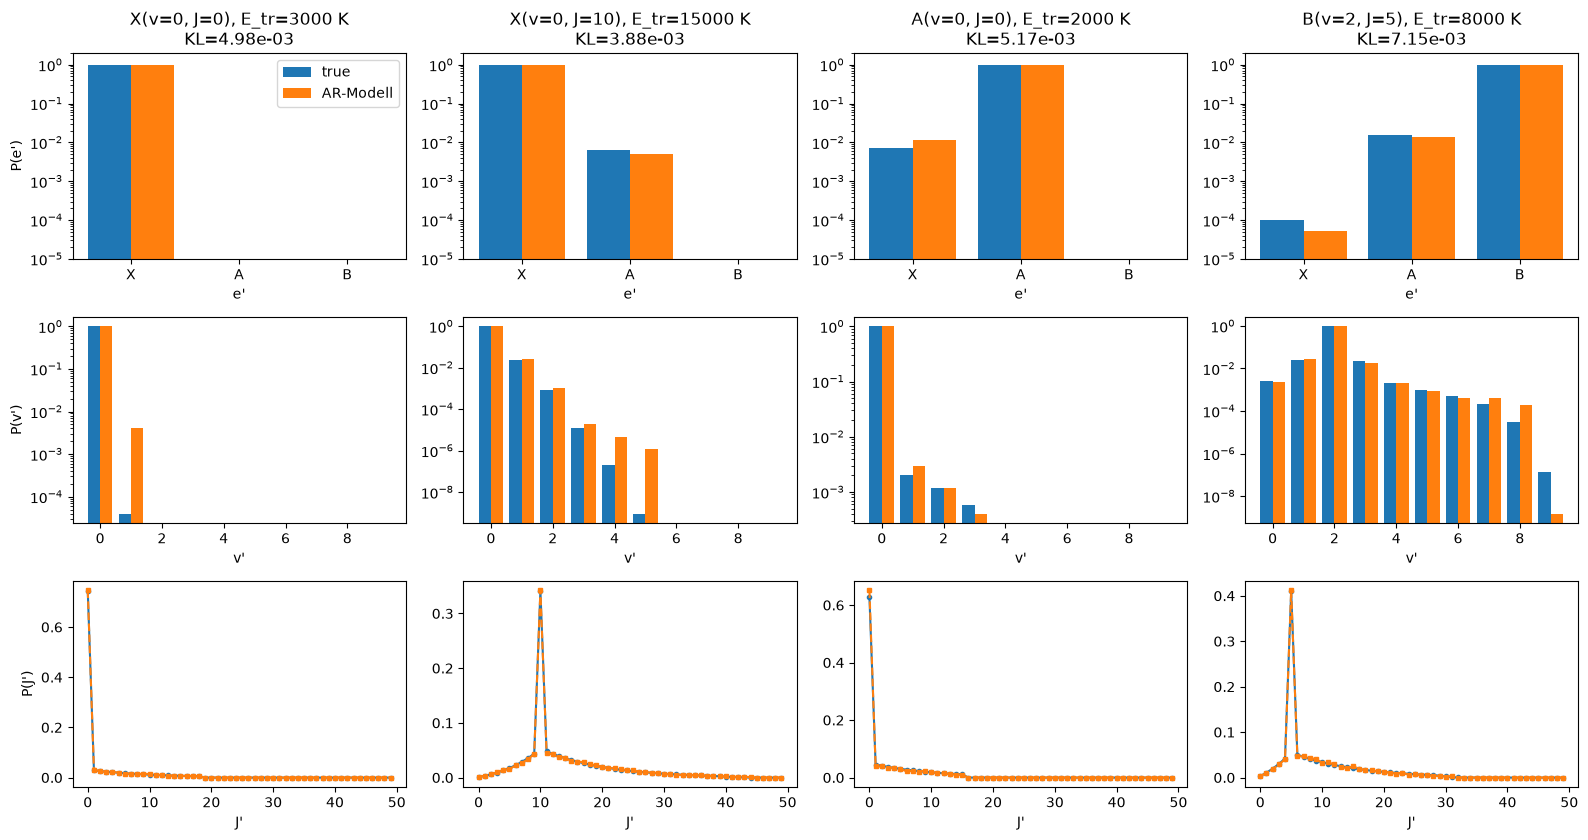

In [14]:
cases = [(0, 0, 0, 3000.0), (0, 0, 10, 15000.0), (1, 0, 0, 2000.0), (2, 2, 5, 8000.0)]
fig, axes = plt.subplots(3, len(cases), figsize=(16, 8.5))
for c, (e0, v0, J0, Etr0) in enumerate(cases):
    i0 = np.array([idx(e0, v0, J0)]); en0 = np.array([Etr0])
    Pt = true_transition_probs(i0, en0)[0].reshape(NE, NV, NJ)
    Pm = model.full_probs(i0.astype(np.int32), en0.astype(np.float32))[0].numpy().astype(np.float64).reshape(NE, NV, NJ)
    kl = np.sum(Pt * (np.log(np.clip(Pt, 1e-300, None)) - np.log(np.clip(Pm, 1e-300, None))))
    x = np.arange(NE)
    axes[0, c].bar(x - 0.2, Pt.sum((1, 2)), 0.4, label="true")
    axes[0, c].bar(x + 0.2, Pm.sum((1, 2)), 0.4, label="AR-Modell")
    axes[0, c].set_xticks(x, EL_NAMES); axes[0, c].set_yscale("log"); axes[0, c].set_xlabel("e'")
    axes[0, c].set_title(f"{EL_NAMES[e0]}(v={v0}, J={J0}), E_tr={Etr0:.0f} K\nKL={kl:.2e}")
    axes[0, c].set_ylim(1e-5, 2)
    axes[1, c].bar(v_idx - 0.2, Pt.sum((0, 2)), 0.4); axes[1, c].bar(v_idx + 0.2, Pm.sum((0, 2)), 0.4)
    axes[1, c].set_yscale("log"); axes[1, c].set_xlabel("v'")
    axes[2, c].plot(J_idx, Pt.sum((0, 1)), "o-", ms=3); axes[2, c].plot(J_idx, Pm.sum((0, 1)), "s--", ms=3)
    axes[2, c].set_xlabel("J'")
axes[0, 0].set_ylabel("P(e')"); axes[1, 0].set_ylabel("P(v')"); axes[2, 0].set_ylabel("P(J')")
axes[0, 0].legend(); plt.tight_layout(); plt.show()

In the quenching case (3rd column) the molecule mostly stays in A (elastic or purely rotational). A small fraction goes to X, and then the released energy ends up largely in the **vibration** of X ($v' = 1\dots3$).

**What to watch out for:** The hardest transitions are those **close to the energy threshold**. There the true probability drops steeply because $E_{\text{tr},f} \to 0$, and the network smooths out this drop. Electronic transitions are additionally **rare** (fraction $\sim 10^{-2}$ of collisions). The likelihood therefore "sees" them little, and small relative errors barely show up in the mean NLL. An electronic channel head that is sampled first makes this visible and controllable.

## 6b. Validation: detailed balance

$$
r_{if} = \log\frac{g_i E_{\text{tr},i}\, p_\theta(f\mid i)}{g_f E_{\text{tr},f}\, p_\theta(i\mid f)} \quad (\text{ideally } = 0)
$$

Evaluated separately for transitions with and without a change of electronic state.

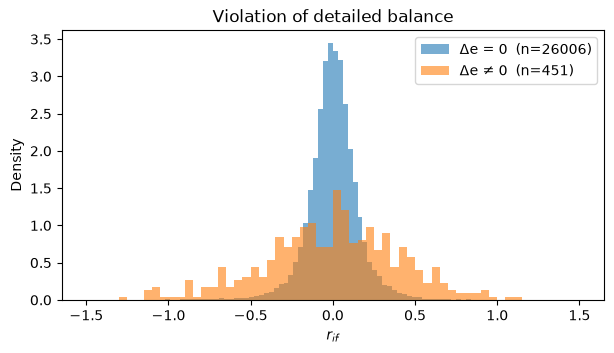

Δe = 0: mean |r| = 0.113, Median r = +0.002
Δe ≠ 0: mean |r| = 0.340, Median r = +0.013


In [15]:
n = 40000
i_s = boltzmann_states(rng.uniform(500, 15000, n), rng)
Etr_s = rng.gamma(2.0, rng.uniform(1000, 15000, n))
f_s = true_sampler(i_s, Etr_s)
m = f_s != i_s
i_s, f_s, Etr_s = i_s[m], f_s[m], Etr_s[m]
Etot_s = Etr_s + eps_flat[i_s]; Etr_f = Etot_s - eps_flat[f_s]

lp_if = model.log_prob(i_s.astype(np.int32), Etr_s.astype(np.float32), f_s.astype(np.int32)).numpy()
lp_fi = model.log_prob(f_s.astype(np.int32), Etr_f.astype(np.float32), i_s.astype(np.int32)).numpy()
r = np.log(g_flat[i_s] * Etr_s) + lp_if - np.log(g_flat[f_s] * Etr_f) - lp_fi
el = e_of[i_s] != e_of[f_s]

plt.figure(figsize=(7, 3.5))
plt.hist(r[~el], bins=100, range=(-1.5, 1.5), density=True, alpha=0.6, label=f"Δe = 0  (n={np.sum(~el)})")
plt.hist(r[el], bins=60, range=(-1.5, 1.5), density=True, alpha=0.6, label=f"Δe ≠ 0  (n={np.sum(el)})")
plt.xlabel(r"$r_{if}$"); plt.ylabel("Density"); plt.legend(); plt.title("Violation of detailed balance")
plt.show()
print(f"Δe = 0: mean |r| = {np.abs(r[~el]).mean():.3f}, Median r = {np.median(r[~el]):+.3f}")
print(f"Δe ≠ 0: mean |r| = {np.abs(r[el]).mean():.3f}, Median r = {np.median(r[el]):+.3f}")

## 6c. Metropolis-Hastings correction: detailed balance by construction

Instead of taking the final state directly from the network, $q_\theta$ is used only as a **proposal**:

1. $f \sim q_\theta(\cdot \mid i, E_\text{tr})$ (normal AR sampling)
2. Accept with
$$
A_{if} = \min\!\left(1,\; \frac{g_f\,E_{\text{tr},f}\;q_\theta(i \mid f, E_{\text{tr},f})}{g_i\,E_{\text{tr},i}\;q_\theta(f \mid i, E_{\text{tr},i})}\right) = \min\big(1, e^{-r_{if}}\big)
$$
3. On rejection the molecule stays in $i$; the collision was elastic.

For $f \neq i$ we then have $g_i E_{\text{tr},i}\,P(f\mid i) = \min\big(g_i E_{\text{tr},i}\,q_\theta(f\mid i),\; g_f E_{\text{tr},f}\,q_\theta(i\mid f)\big)$, which is symmetric under $i \leftrightarrow f$. **Detailed balance holds exactly**, no matter how good the network is. This is only possible because the AR model provides the exact probability $q_\theta(i\mid f)$ of the reverse process.

**Cost:** two additional `log_prob` evaluations per collision, and slightly altered dynamics. Rejected proposals become elastic collisions, so rates drop wherever the network violates detailed balance. How much is shown by the **acceptance rate**. It can be estimated directly from the $r_{if}$ of 6b:

In [16]:
A_test = np.minimum(1.0, np.exp(-r))
print(f"expected acceptance rate (inelastic proposals):  Δe = 0: {A_test[~el].mean():.3f}   Δe ≠ 0: {A_test[el].mean():.3f}")

LOGG_T = tf.constant(np.log(g_flat), tf.float32)

@tf.function(reduce_retracing=True)
def mh_step(i, Etr):
    i = tf.cast(i, tf.int32); Etr = tf.cast(Etr, tf.float32)
    f = model.sample(i, Etr)                                              # proposal
    Etr_f = tf.maximum(Etr + tf.gather(EFLAT_T, i) - tf.gather(EFLAT_T, f), 1e-3)
    lq_fwd = model.log_prob(i, Etr, f)                                    # log q(f | i, E_tr)
    lq_bwd = model.log_prob(f, Etr_f, i)                                  # log q(i | f, E_tr')
    log_A = (tf.gather(LOGG_T, f) + tf.math.log(Etr_f) + lq_bwd) \
          - (tf.gather(LOGG_T, i) + tf.math.log(Etr) + lq_fwd)
    accept = tf.math.log(tf.random.uniform(tf.shape(Etr))) < log_A
    return tf.where(accept, f, i), accept, f

class MHSampler:
    # AR proposal + Metropolis-Hastings acceptance, keeps track of acceptance rates
    def __init__(self):
        self.n = {"all": 0, "el": 0}; self.rej = {"all": 0, "el": 0}
    def __call__(self, i, Etr):
        f_new, acc, f_prop = mh_step(tf.constant(i, tf.int32), tf.constant(Etr, tf.float32))
        f_new, acc, f_prop = f_new.numpy().astype(np.int64), acc.numpy(), f_prop.numpy()
        inel = f_prop != i
        el_ = inel & (e_of[f_prop] != e_of[i])
        self.n["all"] += inel.sum(); self.rej["all"] += (inel & ~acc).sum()
        self.n["el"] += el_.sum();   self.rej["el"] += (el_ & ~acc).sum()
        return f_new
    def report(self):
        return (f"Acceptance rate: all inelastic proposals {1 - self.rej['all'] / max(self.n['all'], 1):.3f}, "
                f"electronic (Δe≠0) {1 - self.rej['el'] / max(self.n['el'], 1):.3f}")

expected acceptance rate (inelastic proposals):  Δe = 0: 0.949   Δe ≠ 0: 0.875


## 6d. What does the model learn, and does it really learn the coupling between e, v and J?

**What is learned.** For every condition $\mathbf c = (e, v, J, E_\text{tr})$ the model must reproduce a full probability table over 1500 final states. It never sees this table. It only sees single samples $f$ drawn from it (section 3b, panel i). It does not store the table. It learns three **classifiers**:

| head | input | output | question it answers |
|---|---|---|---|
| `net_e` | $\mathbf c$ | 3 logits | which electronic state? |
| `net_v` | $\mathbf c$ + one-hot$(e')$ | 10 logits | which $v'$, **given** $e'$? |
| `net_J` | $\mathbf c$ + one-hot$(e')$ + one-hot$(v')$ | 50 logits | which $J'$, **given** $e'$ and $v'$? |

**How it learns (teacher forcing).** During training, $e'$ and $v'$ of the *data* are fed into the later heads. Each head is therefore a plain classifier trained with cross-entropy, and the loss is the sum of the three. The chain rule $p(e',v',J') = p(e')\,p(v'\mid e')\,p(J'\mid e',v')$ is **exact**, not an approximation. Every coupling is therefore *representable*. Whether it is *learned* is an empirical question, and that is what this section tests.

**Where coupling exists in the true physics** (section 2):
1. **$e' \leftrightarrow v'$, explicit:** $a_v(\Delta e)$ is larger when the electronic state changes, so electronic jumps come with large vibrational jumps (E-V transfer in quenching).
2. **$v' \leftrightarrow J'$ (and $e'$), through energy:** all three share $E_\text{tot}$. The acceptance factor $\propto g_f\,E_{\text{tr},f} = g_f\,(E_\text{tot} - \varepsilon_f)$ makes high $J'$ less likely when $v'$ is already high. The energy masks enforce only the *hard* limit $\varepsilon_f < E_\text{tot}$. The *soft* shape below that limit has to be learned.
3. **Elastic peak:** $f = i$ means $v' = v$ **and** $J' = J$ at the same time, a strong joint correlation.

The kernel $K_{if}$ itself factorizes in $|\Delta e|, |\Delta v|, |\Delta J|$. Without the energy constraint and the $\Delta e$-dependent $a_v$ there would be hardly any coupling.

**Tests:**
- **(A) Conditional slices:** $p(J' \mid e'{=}X, v', \mathbf c)$ for different $v'$, true vs. model. A model *without* coupling would give the same curve (the black marginal) for every $v'$.
- **(B) E-V coupling in quenching:** $p(v' \mid e', \mathbf c)$ for $e' = X$ vs. $e' = A$.
- **(C) Joint vs. product:** the true joint $p(v', J')$, the model's joint, and the product of the marginals $p(v')\,p(J')$, i.e. what a factorized model would produce.
- **(D) Quantitative test over many conditions:** the **total correlation** $\mathrm{TC} = \mathrm{KL}\big(P \,\|\, P(e')P(v')P(J')\big)$ measures how much information sits in the coupling. It is exactly the error that the *best possible* factorized model $q(e')q(v')q(J')$ would make. If $\mathrm{KL}(P_\text{true}\,\|\,p_\theta) \ll \mathrm{TC}$, the model has captured the coupling.

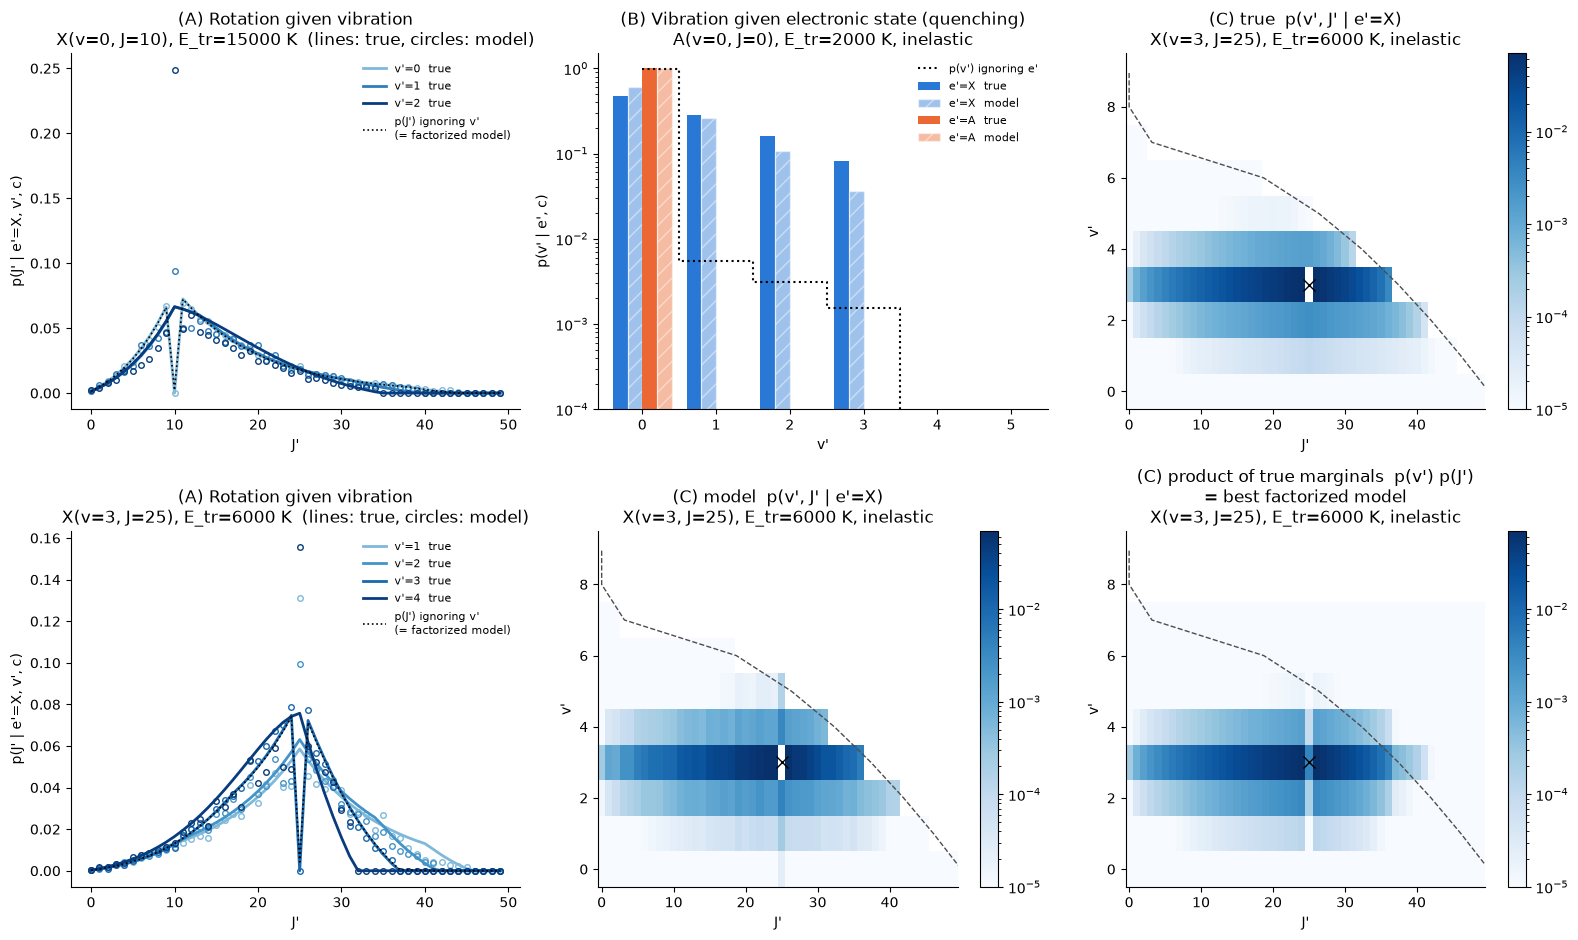

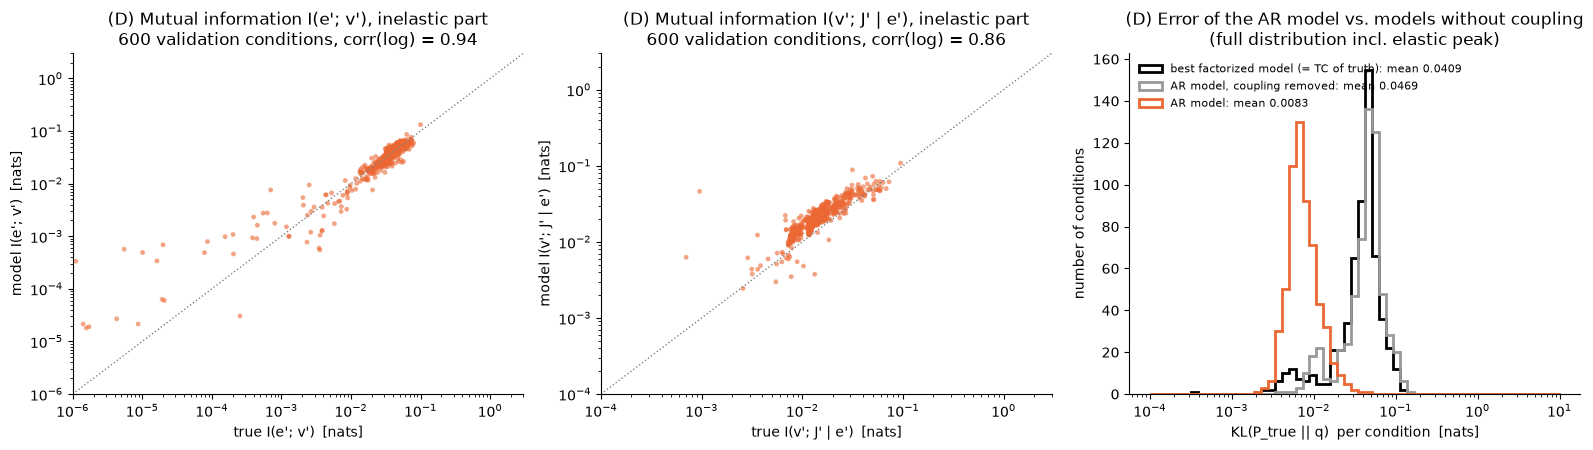

Mean over 600 validation conditions [nats]       full distribution   inelastic part
  coupling in the truth (TC)                     0.0409           0.0547
  coupling in the model (TC)                     0.0378           0.0627
  KL(true || AR)                                 0.0083           0.0128
  KL(true || AR, coupling removed)               0.0469           0.0647
Share of the true coupling the model captures (full): 1 - KL / KL_without_coupling = 82.3%
Share of the true coupling the model captures (inelastic): 1 - KL / KL_without_coupling = 80.2%


In [17]:
# Does the AR model learn the coupling between e', v', J'?
from matplotlib.colors import LogNorm

COL = {"true": "#2a78d6", "model": "#eb6834"}
EL_COL = ["#2a78d6", "#eb6834", "#1baf7a"]
sname = lambda s: f"{EL_NAMES[e_of[s]]}(v={v_of[s]}, J={J_of[s]})"

def joint(i, Etr, inelastic=False):
    # true and model distributions over (e', v', J'), shape (N, NE, NV, NJ), float64
    i = np.atleast_1d(i); Etr = np.atleast_1d(np.asarray(Etr, float))
    Pt = true_transition_probs(i, Etr)
    Pm = model.full_probs(i.astype(np.int32), Etr.astype(np.float32)).numpy().astype(np.float64)
    Pm /= Pm.sum(1, keepdims=True)
    if inelastic:                                  # drop the elastic peak f = i and renormalize
        for P in (Pt, Pm):
            P[np.arange(len(i)), i] = 0.0
            P /= P.sum(1, keepdims=True)
    return Pt.reshape(-1, NE, NV, NJ), Pm.reshape(-1, NE, NV, NJ)

def _kl(P, Q, axes):
    with np.errstate(divide="ignore", invalid="ignore"):
        t = np.where(P > 0, P * (np.log(P) - np.log(np.clip(Q, 1e-300, None))), 0.0)
    return t.sum(axes)

def coupling_stats(P):
    # P: (N, NE, NV, NJ). Returns I(e';v'), I(v';J' | e'), total correlation (all in nats)
    Pe, Pv, PJ = P.sum((2, 3)), P.sum((1, 3)), P.sum((1, 2))
    Pev, PeJ = P.sum(3), P.sum(2)
    ax = (1, 2, 3)
    I_ev = _kl(Pev, Pe[:, :, None] * Pv[:, None, :], (1, 2))
    with np.errstate(divide="ignore", invalid="ignore"):
        Q = Pev[..., None] * PeJ[:, :, None, :] / Pe[:, :, None, None]
    I_vJ_e = _kl(P, np.nan_to_num(Q), ax)
    TC = _kl(P, Pe[:, :, None, None] * Pv[:, None, :, None] * PJ[:, None, None, :], ax)
    return I_ev, I_vJ_e, TC

# ---------------------------------------------------------------- (A) + (B) + (C)
fig, ax = plt.subplots(2, 3, figsize=(16, 9.5))
for a in ax.flat:
    a.spines[["top", "right"]].set_visible(False)

# (A) p(J' | e'=X, v', c) for several v': does the J head react to v'?
for row, (i_c, E_c) in enumerate([(idx(0, 0, 10), 15000.0), (idx(0, 3, 25), 6000.0)]):
    a = ax[row, 0]
    Pt, Pm = joint(i_c, E_c, inelastic=True)
    Pt, Pm = Pt[0], Pm[0]
    pJ_marg = Pt[0].sum(0) / Pt[0].sum()                       # p(J' | e'=X), ignores v'
    vs = [v for v in range(NV) if Pt[0, v].sum() > 1e-4][:4]
    shades = plt.cm.Blues(np.linspace(0.45, 0.95, len(vs)))
    for v, sh in zip(vs, shades):
        a.plot(J_idx, Pt[0, v] / Pt[0, v].sum(), color=sh, lw=2, label=f"v'={v}  true")
        a.plot(J_idx, Pm[0, v] / Pm[0, v].sum(), color=sh, lw=0, marker="o", ms=4, mfc="none")
    a.plot(J_idx, pJ_marg, color="black", lw=1.2, ls=":", label="p(J') ignoring v'\n(= factorized model)")
    a.set(xlabel="J'", ylabel="p(J' | e'=X, v', c)",
          title=f"(A) Rotation given vibration\n{sname(i_c)}, E_tr={E_c:.0f} K  (lines: true, circles: model)")
    a.legend(frameon=False, fontsize=8)

# (B) p(v' | e', c) in quenching: does the v head react to e'?
a = ax[0, 1]
i_q, E_q = idx(1, 0, 0), 2000.0
Pt, Pm = joint(i_q, E_q, inelastic=True)
Pt, Pm = Pt[0], Pm[0]
w = 0.2
for k, e in enumerate([0, 1]):
    pt, pm = Pt[e].sum(1), Pm[e].sum(1)
    a.bar(v_idx + (2 * k - 1.5) * w, pt / pt.sum(), w, color=EL_COL[e], label=f"e'={EL_NAMES[e]}  true")
    a.bar(v_idx + (2 * k - 0.5) * w, pm / pm.sum(), w, color=EL_COL[e], alpha=0.45,
          hatch="//", edgecolor="white", label=f"e'={EL_NAMES[e]}  model")
pv_marg = Pt.sum((0, 2))
a.step(v_idx, pv_marg / pv_marg.sum(), where="mid", color="black", ls=":", label="p(v') ignoring e'")
a.set(yscale="log", ylim=(1e-4, 1.5), xlabel="v'", ylabel="p(v' | e', c)", xlim=(-0.6, 5.5),
      title=f"(B) Vibration given electronic state (quenching)\n{sname(i_q)}, E_tr={E_q:.0f} K, inelastic")
a.legend(frameon=False, fontsize=8)

# (C) joint p(v', J' | e'=X): true / model / product of marginals
i_c, E_c = idx(0, 3, 25), 6000.0
Pt, Pm = joint(i_c, E_c, inelastic=True)
jt, jm = Pt[0, 0] / Pt[0, 0].sum(), Pm[0, 0] / Pm[0, 0].sum()
prod = np.outer(jt.sum(1), jt.sum(0))
norm = LogNorm(vmin=1e-5, vmax=jt.max())
for a, M, ttl in [(ax[0, 2], jt, "true  p(v', J' | e'=X)"),
                  (ax[1, 1], jm, "model  p(v', J' | e'=X)"),
                  (ax[1, 2], prod, "product of true marginals  p(v') p(J')\n= best factorized model")]:
    im = a.imshow(np.where(M > 0, M, np.nan), aspect="auto", origin="lower", cmap="Blues", norm=norm)
    a.plot(J_of[i_c], v_of[i_c], "x", color="black", ms=8)
    J_max = np.sqrt(np.clip(E_c + eps_flat[i_c] - eps_vib[0], 0, None) / B_ROT)   # energy limit
    a.plot(J_max, v_idx, color="0.3", lw=1, ls="--")
    a.set(xlabel="J'", ylabel="v'", xlim=(-0.5, NJ - 0.5), ylim=(-0.5, NV - 0.5),
          title=f"(C) {ttl}\n{sname(i_c)}, E_tr={E_c:.0f} K, inelastic")
    fig.colorbar(im, ax=a)
fig.tight_layout(); plt.show()

# ---------------------------------------------------------------- (D) many conditions
n_c = 600
sel = va[:n_c]
I_c, E_cs = I_all[sel], E_all[sel]
def factorize(P):
    # product of the marginals of P: the same distribution with all coupling removed
    return P.sum((2, 3))[:, :, None, None] * P.sum((1, 3))[:, None, :, None] * P.sum((1, 2))[:, None, None, :]

stats = {}
for inel in (False, True):
    Pt, Pm = joint(I_c, E_cs, inelastic=inel)
    stats[inel] = dict(true=coupling_stats(Pt), model=coupling_stats(Pm),
                       kl=_kl(Pt, Pm, (1, 2, 3)),                     # AR model
                       kl_fact=_kl(Pt, factorize(Pm), (1, 2, 3)))     # AR model with its coupling removed

fig, ax = plt.subplots(1, 3, figsize=(16, 4.6))
for a in ax:
    a.spines[["top", "right"]].set_visible(False)
for a, k, lab in [(ax[0], 0, "I(e'; v')"), (ax[1], 1, "I(v'; J' | e')")]:
    t, m = stats[True]["true"][k], stats[True]["model"][k]
    ok = (t > 1e-6) & (m > 1e-6)
    lo = 10 ** np.floor(np.log10(min(t[ok].min(), m[ok].min())))
    a.loglog([lo, 3], [lo, 3], color="0.5", lw=1, ls=":")
    a.scatter(t, m, s=12, color=COL["model"], alpha=0.6, edgecolors="none")
    r = np.corrcoef(np.log(t[ok]), np.log(m[ok]))[0, 1]
    a.set(xlabel=f"true {lab}  [nats]", ylabel=f"model {lab}  [nats]", xlim=(lo, 3), ylim=(lo, 3),
          title=f"(D) Mutual information {lab}, inelastic part\n{n_c} validation conditions, corr(log) = {r:.2f}")

# How much does the model's coupling help? Compare with the same model, coupling removed
a = ax[2]
s_ = stats[False]
bins = np.logspace(-4, 1, 60)
for vals, col, lab in [(s_["true"][2], "black", "best factorized model (= TC of truth)"),
                       (s_["kl_fact"], "0.6", "AR model, coupling removed"),
                       (s_["kl"], COL["model"], "AR model")]:
    a.hist(vals, bins=bins, histtype="step", lw=2, color=col, label=f"{lab}: mean {vals.mean():.4f}")
a.set(xscale="log", xlabel="KL(P_true || q)  per condition  [nats]", ylabel="number of conditions",
      title="(D) Error of the AR model vs. models without coupling\n(full distribution incl. elastic peak)")
a.legend(frameon=False, fontsize=8, loc="upper left")
fig.tight_layout(); plt.show()

print(f"Mean over {n_c} validation conditions [nats]       full distribution   inelastic part")
for key, lab in [("tc_true", "coupling in the truth (TC)"), ("tc_model", "coupling in the model (TC)"),
                 ("kl", "KL(true || AR)"), ("kl_fact", "KL(true || AR, coupling removed)")]:
    get = lambda d: d["true"][2] if key == "tc_true" else d["model"][2] if key == "tc_model" else d[key]
    print(f"  {lab:40s} {get(stats[False]).mean():12.4f} {get(stats[True]).mean():16.4f}")
for inel, lab in [(False, "full"), (True, "inelastic")]:
    d = stats[inel]
    print(f"Share of the true coupling the model captures ({lab}): "
          f"1 - KL / KL_without_coupling = {1 - d['kl'].mean() / d['kl_fact'].mean():.1%}")

**Interpretation** (numbers from one training run, they vary slightly between runs)

- **The coupling is learned to a large extent.** Removing the coupling from the trained model (product of its own marginals) raises the mean KL from ≈ 0.008 to ≈ 0.047 nats. The model thus captures roughly **80 %** of the information that sits in the coupling. The mutual information of the model follows the true one over orders of magnitude (D, left and middle).
- **E-V coupling (B):** the $v$ head clearly uses $e'$. If the molecule stays in A, $v' = 0$. If it is quenched to X, the vibration gets excited ($v' = 1\dots3$). A factorized model (dotted) could not do this at all. The tail ($v' = 2, 3$) is **underestimated**, though, i.e. too little E-V transfer per quench event. Rare channels are hard to learn (cf. 6a).
- **Weak spot: the elastic peak leaks (A, C).** In the truth, $J' = J$ is special *only* if also $v' = v$ and $e' = e$ (then it is elastic). The model puts too much probability on $J' = J$ even when $v'$ has changed (spikes in A, vertical stripe in C). To get this right, the $J$ head has to *compare* one-hot($v'$) with one-hot($v$), an XOR-like function that the MLP learns only imperfectly. This is also why the model *over*estimates $I(v'; J' \mid e')$ (D, middle).
- **The $v'$–$J'$ coupling via energy is weak in this toy system** (A: the true curves for different $v'$ hardly differ, except close to the energy limit). Most of the energy coupling is enforced by the **masks** for free, not learned.

**Possible improvements:** give the heads *relative* inputs (e.g. $\Delta e = e' - e$, $\Delta v = v' - v$ and the flag $[e' = e \wedge v' = v]$) instead of only absolute one-hots, or model the elastic channel with its own head ("elastic yes/no" first, then the AR chain over the inelastic states).

### Summary: does the model learn the complete coupling of all states?

Two questions have to be separated.

**a) Can the model represent the complete coupling? Yes, fully.**
- *Before → after:* every head receives the complete initial state $(e, v, J)$ and $E_\text{tr}$. Each of the 1500 initial states can therefore be linked to each of the 1500 final states.
- *$e' \leftrightarrow v' \leftrightarrow J'$ among each other:* the chain rule yields the full table with 1500 numbers per condition (see section 4), not just 63.

**b) Does it actually learn it? Largely, but not perfectly** (see the tests above):
- Overall it captures about 80 % of the information contained in the coupling. Removing its coupling artificially makes the error about six times larger.
- $e' \to v'$ is learned: in quenching to X, the energy ends up in vibration as in the truth, though somewhat too weakly.
- What is not learned cleanly is the rule "$J' = J$ is special only if also $v' = v$ and $e' = e$" (the elastic collision). The model sets $J' = J$ too often even when $v'$ has changed.

**In short:** the architecture can represent the complete coupling of all $1500 \times 1500$ transitions. It learns it only as well as the data and the network allow, i.e. well for frequent transitions and worse for rare or "logical" relations such as the elastic case.

## 7. 0D DSMC heat bath

A homogeneous cell with $N_A$ A₂ molecules and $N_B$ B atoms. Only A₂–B collisions occur: NTC with constant $\sigma_\text{ref}$ (hard spheres), final state from the **sampler** (AR model or truth), $E_\text{tr}' = E_\text{tr} + \varepsilon_i - \varepsilon_f$, isotropic scattering in the center-of-mass frame.

Three samplers are compared: the **true** collision physics, the **AR** model directly, and **AR+MH** (AR proposal with Metropolis-Hastings acceptance, section 6c).

Diagnostics:
- $T_\text{tr}$ from the kinetic energy, $T_\text{rot}$ from $\langle \varepsilon_\text{rot}\rangle$ of all molecules
- $T_\text{vib}$ from $\langle \varepsilon_\text{vib}\rangle$ of the molecules **in the ground state X**, because each electronic state has its own vibrational ladder
- **electronic populations** $x_X, x_A, x_B$ directly
- **electronic excitation temperatures**, defined as in spectroscopy via population ratios:
$$
\frac{x_A}{x_X} = \frac{Q_A(T_\text{el}^{A})}{Q_X(T_\text{el}^{A})}, \qquad
\frac{x_B}{x_X} = \frac{Q_B(T_\text{el}^{B})}{Q_X(T_\text{el}^{B})}, \qquad
Q_e(T) = \sum_{v,J} g_e (2J+1)\, e^{-\varepsilon(e,v,J)/T}
$$
  The partition functions $Q_e$ include the vibrational and rotational levels of the respective electronic state. In equilibrium, the definition then yields exactly $T_\text{eq}$. Two properties are important:
  - $T_\text{el}^{A} \neq T_\text{el}^{B}$ means that the electronic states are not in equilibrium **with each other**. There is then no single electronic temperature.
  - If $x_A/x_X$ exceeds the limit for $T \to \infty$ (here $g_A/g_X = 3$), there is a **population inversion**. Formally $T_\text{el} < 0$, and the plot shows a gap. This is exactly what happens at the start of the quenching scenario.

Equilibrium: $\tfrac32 (N_A + N_B)\,T_\text{eq} + N_A\,\langle\varepsilon\rangle(T_\text{eq}) = E_\text{tot}$, where $\langle\varepsilon\rangle$ is averaged over **all** 1500 levels.

In [18]:
M_A, M_B = 28.0, 14.0
MU = M_A * M_B / (M_A + M_B)

T_grid = np.linspace(20, 40000, 6000)
def mean_energy_curve(levels, g):
    out = np.empty(len(T_grid))
    for k in range(0, len(T_grid), 500):
        w = g[None, :] * np.exp(-(levels[None, :] - levels.min()) / T_grid[k:k+500, None])
        out[k:k+500] = (w * levels).sum(1) / w.sum(1)
    return out
Erot_curve = mean_energy_curve(eps_rot, g_rot)
EvibX_curve = mean_energy_curve(eps_vib[0], np.ones(NV))
Eint_curve = mean_energy_curve(eps_flat, g_flat)
T_from = lambda E, curve: np.interp(E, curve, T_grid)

# log Q_e(T) for each electronic state (log-sum-exp against underflow at small T)
logQ = np.empty((NE, len(T_grid)))
for e in range(NE):
    lev, g = eps_flat[e_of == e], g_flat[e_of == e]
    a = np.log(g)[None, :] - lev[None, :] / T_grid[:, None]
    amax = a.max(1)
    logQ[e] = amax + np.log(np.exp(a - amax[:, None]).sum(1))
logR = logQ - logQ[0]          # log(Q_e / Q_X), monotonically increasing in T

def T_el_from_pops(x, e):
    # Excitation temperature from x_e / x_X. NaN if population is missing or inverted
    if x[e] <= 0 or x[0] <= 0:
        return np.nan
    lr = np.log(x[e] / x[0])
    if lr > logR[e, -1] or lr < logR[e, 0]:
        return np.nan
    return np.interp(lr, logR[e], T_grid)

def boltzmann_pops(T):
    w = g_flat * np.exp(-eps_flat / T); w /= w.sum()
    return (np.bincount(e_of, w, NE), np.bincount(v_of[e_of == 0], w[e_of == 0], NV) / w[e_of == 0].sum(),
            np.bincount(J_of, w, NJ))

def T_equilibrium(E_tot, N_A, N_B):
    return T_grid[np.argmin(np.abs(1.5 * (N_A + N_B) * T_grid + N_A * Eint_curve - E_tot))]

def random_unit(n, rng):
    u = rng.normal(size=(n, 3)); return u / np.linalg.norm(u, axis=1, keepdims=True)

def run_heatbath(sampler, T_tr0, s0, N_A=10000, N_B=10000, n_steps=3000,
                 cand_per_step=3000, seed=1, record_every=20, snap_at=()):
    rng = np.random.default_rng(seed)
    vA = rng.normal(0, np.sqrt(T_tr0 / M_A), (N_A, 3))
    vB = rng.normal(0, np.sqrt(T_tr0 / M_B), (N_B, 3))
    P = M_A * vA.sum(0) + M_B * vB.sum(0)
    vA -= P / (M_A * N_A + M_B * N_B); vB -= P / (M_A * N_A + M_B * N_B)
    state = np.full(N_A, s0, dtype=np.int64)
    g_max, n_coll = 1.0, 0
    rec = {"t": [], "Ttr": [], "Trot": [], "Tvib": [], "TelA": [], "TelB": [], "Etot": [], "xel": [],
           "Erot": [], "Evib": [], "Eel": []}
    snaps = {}
    for step in range(n_steps + 1):
        for s in snap_at:
            if s not in snaps and n_coll / N_A >= s:
                snaps[s] = state.copy()
        if step % record_every == 0:
            Ekin = 0.5 * M_A * (vA**2).sum() + 0.5 * M_B * (vB**2).sum()
            inX = e_of[state] == 0
            rec["t"].append(n_coll / N_A)
            rec["Ttr"].append(Ekin / (1.5 * (N_A + N_B)))
            rec["Trot"].append(T_from(eps_rot[J_of[state]].mean(), Erot_curve))
            rec["Tvib"].append(T_from(eps_vib[0][v_of[state[inX]]].mean(), EvibX_curve) if inX.any() else np.nan)
            rec["Etot"].append(Ekin + eps_flat[state].sum())
            rec["Erot"].append(eps_rot[J_of[state]].mean())
            rec["Evib"].append(eps_vib[e_of[state], v_of[state]].mean())
            rec["Eel"].append(EL_T[e_of[state]].mean())
            x_el = np.bincount(e_of[state], minlength=NE) / N_A
            rec["xel"].append(x_el)
            rec["TelA"].append(T_el_from_pops(x_el, 1))
            rec["TelB"].append(T_el_from_pops(x_el, 2))
        a = rng.permutation(N_A)[:cand_per_step]
        b = rng.permutation(N_B)[:cand_per_step]
        g = np.linalg.norm(vA[a] - vB[b], axis=1)
        g_max = max(g_max, g.max())
        acc = rng.random(len(g)) < g / g_max
        a, b, g = a[acc], b[acc], g[acc]
        Etr = 0.5 * MU * g**2
        i = state[a]
        f = sampler(i, Etr)
        Etr_new = np.maximum(Etr + eps_flat[i] - eps_flat[f], 0.0)   # guard against float32 rounding
        g_new = np.sqrt(2 * Etr_new / MU)[:, None] * random_unit(len(a), rng)
        Vcm = (M_A * vA[a] + M_B * vB[b]) / (M_A + M_B)
        vA[a] = Vcm + M_B / (M_A + M_B) * g_new
        vB[b] = Vcm - M_A / (M_A + M_B) * g_new
        state[a] = f
        n_coll += len(a)
    out = {k: np.array(v) for k, v in rec.items()}
    out["snaps"], out["N"] = snaps, (N_A, N_B)
    return out, state

def model_sampler(i, Etr):
    return model.sample(tf.constant(i, tf.int32), tf.constant(Etr, tf.float32)).numpy().astype(np.int64)

# Plot style per variant: (name, line style)
STYLE = {"true": dict(lw=2.8, alpha=0.4), "AR": dict(ls="--", lw=1.5), "AR+MH": dict(ls=":", lw=2.0)}

def plot_run(runs, title, log_pop=False, T_ylim=None):
    # runs: dict name -> result of run_heatbath, e.g. {"true": ..., "AR": ..., "AR+MH": ...}
    ref = runs["true"]
    T_eq = T_equilibrium(ref["Etot"][0], *ref["N"])
    pe_eq = boltzmann_pops(T_eq)[0]
    fig, ax = plt.subplots(1, 2, figsize=(16, 4.8))
    for key, c in [("Ttr", "C0"), ("Trot", "C1"), ("Tvib", "C2"), ("TelA", "C4"), ("TelB", "C5")]:
        for name, r in runs.items():
            ax[0].plot(r["t"], r[key], color=c, label=f"{key} {name}", **STYLE[name])
    ax[0].axhline(T_eq, color="gray", lw=0.8)
    if T_ylim: ax[0].set_ylim(*T_ylim)
    ax[0].set_xlabel("Collisions per molecule"); ax[0].set_ylabel("Temperature [K]")
    ax[0].set_title(f"{title}: temperatures (T_eq = {T_eq:.0f} K)"); ax[0].legend(ncol=3, fontsize=7)
    for e in range(NE):
        for name, r in runs.items():
            ax[1].plot(r["t"], r["xel"][:, e], color=f"C{e+3}", label=f"{EL_NAMES[e]} {name}", **STYLE[name])
        ax[1].axhline(pe_eq[e], color=f"C{e+3}", lw=0.8, ls="-.")
    if log_pop: ax[1].set_yscale("log"); ax[1].set_ylim(1e-5, 1.5)
    ax[1].set_xlabel("Collisions per molecule"); ax[1].set_ylabel("Population")
    ax[1].set_title(f"{title}: electronic populations (dash-dotted: Boltzmann at T_eq)")
    ax[1].legend(ncol=3, fontsize=7)
    plt.tight_layout(); plt.show()

    late = slice(len(ref["t"]) * 3 // 4, None)          # time average over the last quarter
    print(f"T_eq = {T_eq:.0f} K,  Boltzmann x_el = {np.round(pe_eq, 4)}")
    for name, r in runs.items():
        print(f"  {name:6s}: T_tr={r['Ttr'][late].mean():.0f}  T_rot={r['Trot'][late].mean():.0f}  "
              f"T_vib(X)={np.nanmean(r['Tvib'][late]):.0f}  T_el(A)={np.nanmean(r['TelA'][late]):.0f}  "
              f"T_el(B)={np.nanmean(r['TelB'][late]):.0f}  x_el={np.round(r['xel'][late].mean(0), 4)}")
    for name, r in runs.items():
        if name != "true":
            print(f"  Energy conservation (rel. drift) {name}: {abs(r['Etot'][-1] / r['Etot'][0] - 1):.1e}")
    return T_eq

def plot_energy_relaxation(runs, title):
    # Normalized energy content per mode: 0 = start, 1 = final value (average over the last quarter)
    fig, ax = plt.subplots(figsize=(9, 4.2))
    print(f"1/e relaxation times (energy) in collisions per molecule, {title}:")
    for key, c, lab in [("Erot", "C1", "Rotation"), ("Evib", "C2", "Vibration"), ("Eel", "C4", "electronic")]:
        taus = {}
        for name, r in runs.items():
            E = r[key]; E_end = E[-len(E) // 4:].mean()
            y = (E - E[0]) / (E_end - E[0])
            ax.plot(r["t"][1:], y[1:], color=c, label=f"{lab} {name}", **STYLE[name])   # t=0 does not fit on the log axis
            k = np.argmax(y > 1 - np.exp(-1))
            taus[name] = np.interp(1 - np.exp(-1), [y[k-1], y[k]], [r["t"][k-1], r["t"][k]])
        print(f"  {lab:13s} " + "   ".join(f"{n} = {t:6.1f}" for n, t in taus.items()))
    ax.axhline(1 - np.exp(-1), color="gray", lw=0.8, ls=":")
    ax.set_xscale("log"); ax.set_xlim(runs["true"]["t"][1], None)
    ax.set_xlabel("Collisions per molecule (log)"); ax.set_ylabel("normalized energy content")
    ax.set_title(f"{title}: relaxation of energy contents"); ax.legend(ncol=3, fontsize=7)
    plt.show()

### Scenario 1: Heating

Start: $T_\text{tr} = 10000$ K, all molecules in $X(v{=}0, J{=}0)$. Expected order: **rotation first** (a few collisions), then vibration and electronic excitation.

**Caution when reading the temperature curves:** $T_\text{vib}$ and $T_\text{el}$ quickly jump to several thousand Kelvin at the start, even though hardly any energy is in these modes. This is due to the nonlinear definition. For large quantum spacings ($\hbar\omega \approx 3000$ K), roughly $\langle\varepsilon_\text{vib}\rangle \approx \hbar\omega\,e^{-\hbar\omega/T}$. Just a few percent of molecules in $v=1$ therefore mean $T_\text{vib} \approx 1000$ K. To answer "which mode relaxes first", the **normalized energy content** is the right measure (second plot, log time axis).

true: 223s
AR: 53s
AR+MH: 110s
Acceptance rate: all inelastic proposals 0.944, electronic (Δe≠0) 0.809


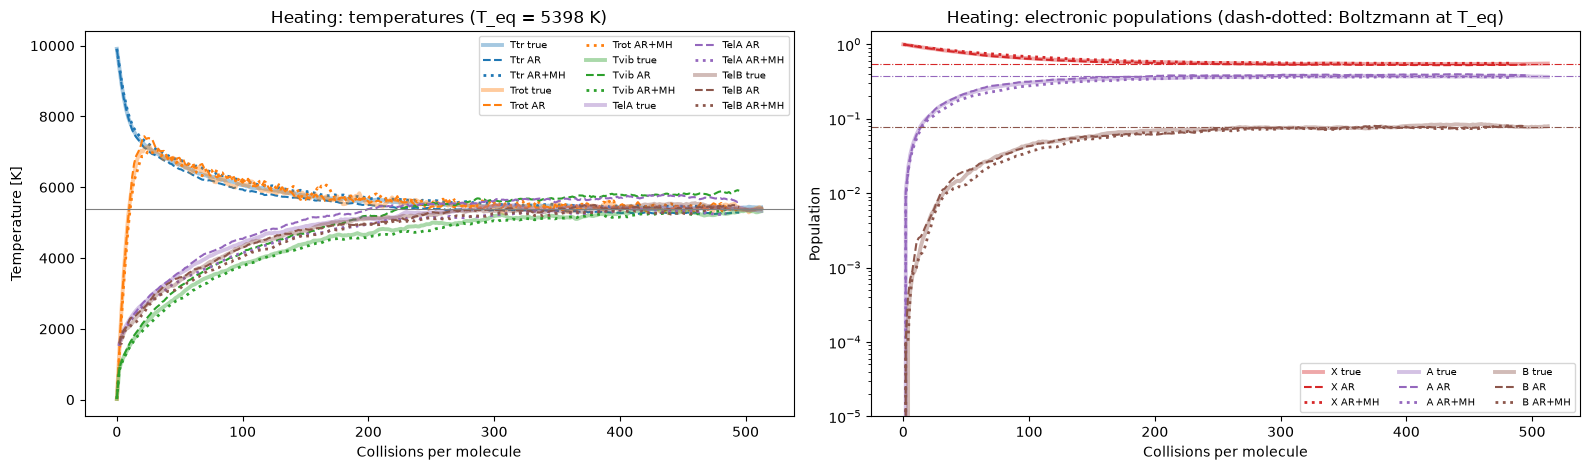

T_eq = 5398 K,  Boltzmann x_el = [0.5496 0.3716 0.0788]
  true  : T_tr=5415  T_rot=5414  T_vib(X)=5298  T_el(A)=5406  T_el(B)=5457  x_el=[0.5477 0.3712 0.0811]
  AR    : T_tr=5277  T_rot=5413  T_vib(X)=5798  T_el(A)=5709  T_el(B)=5429  x_el=[0.53   0.3927 0.0773]
  AR+MH : T_tr=5461  T_rot=5471  T_vib(X)=5242  T_el(A)=5312  T_el(B)=5313  x_el=[0.5572 0.3666 0.0762]
  Energy conservation (rel. drift) AR: 2.0e-14
  Energy conservation (rel. drift) AR+MH: 2.0e-14
1/e relaxation times (energy) in collisions per molecule, Heating:
  Rotation      true =    4.8   AR =    4.7   AR+MH =    5.3
  Vibration     true =   75.8   AR =   72.5   AR+MH =   79.5
  electronic    true =   74.1   AR =   75.0   AR+MH =   88.8


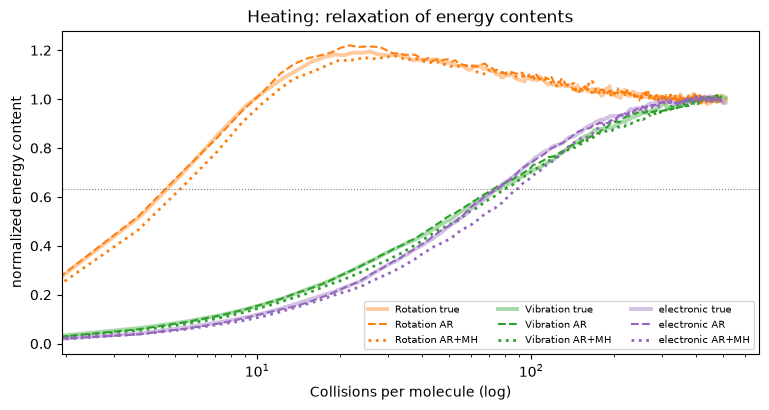

In [19]:
rng_true = np.random.default_rng(7)
runs1, final1 = {}, {}
for name, sampler in [("true", lambda i, e: true_sampler(i, e, rng_true)),
                      ("AR", model_sampler),
                      ("AR+MH", (mh1 := MHSampler()))]:
    t0 = time.time()
    runs1[name], final1[name] = run_heatbath(sampler, 10000.0, idx(0, 0, 0), n_steps=7000)
    print(f"{name}: {time.time()-t0:.0f}s")
print(mh1.report())
T_eq1 = plot_run(runs1, "Heating", log_pop=True)
plot_energy_relaxation(runs1, "Heating")

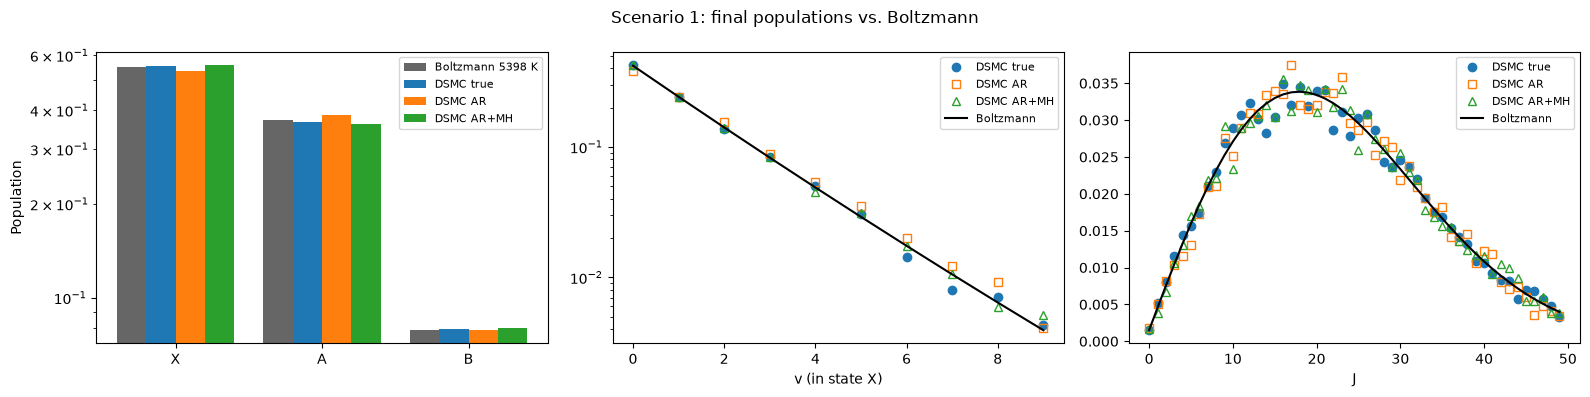

In [20]:
pe_eq, pvX_eq, pJ_eq = boltzmann_pops(T_eq1)
N1 = runs1["true"]["N"][0]
MARK = {"true": dict(marker="o", ls=""), "AR": dict(marker="s", mfc="none", ls=""), "AR+MH": dict(marker="^", mfc="none", ls="")}
fig, ax = plt.subplots(1, 3, figsize=(16, 4))
x = np.arange(NE); w = 0.2
ax[0].bar(x - 1.5 * w, pe_eq, w, color="k", alpha=0.6, label=f"Boltzmann {T_eq1:.0f} K")
for k, (name, st) in enumerate(final1.items()):
    ax[0].bar(x + (k - 0.5) * w, np.bincount(e_of[st], minlength=NE) / N1, w, label=f"DSMC {name}")
    stX = st[e_of[st] == 0]
    ax[1].semilogy(v_idx, np.bincount(v_of[stX], minlength=NV) / len(stX), label=f"DSMC {name}", **MARK[name])
    ax[2].plot(J_idx, np.bincount(J_of[st], minlength=NJ) / N1, label=f"DSMC {name}", **MARK[name])
ax[0].set_xticks(x, EL_NAMES); ax[0].set_yscale("log"); ax[0].set_ylabel("Population"); ax[0].legend(fontsize=8)
ax[1].semilogy(v_idx, pvX_eq, "k-", label="Boltzmann"); ax[1].set_xlabel("v (in state X)"); ax[1].legend(fontsize=8)
ax[2].plot(J_idx, pJ_eq, "k-", label="Boltzmann"); ax[2].set_xlabel("J"); ax[2].legend(fontsize=8)
plt.suptitle("Scenario 1: final populations vs. Boltzmann"); plt.tight_layout(); plt.show()

## 8. Scenario 2: Quenching of electronic excitation

Start: **all molecules in the excited state A** $(v{=}0, J{=}0)$, the gas is cold ($T_\text{tr} = 1000$ K). Roughly the situation after laser excitation or behind electron-impact excitation in a plasma.

The excitation (9000 K per molecule) is removed in collisions. Part of the energy goes directly into **ground-state vibration** (E-V) and part into translation and rotation (E-T, E-R). The gas heats up.

Of particular interest here:
1. the **quench rate**, i.e. how fast $x_A$ decays, and the electronic excitation temperature $T_\text{el}^A$: initially population inversion (gap in the plot), then it falls from very high values to $T_\text{eq}$,
2. the **non-thermal vibrational distribution** in X during quenching, with an excess in $v = 1\dots3$ due to E-V transfer,
3. the new equilibrium with a small residual population in A.

true: 232s
AR: 56s
AR+MH: 130s
Acceptance rate: all inelastic proposals 0.925, electronic (Δe≠0) 0.757


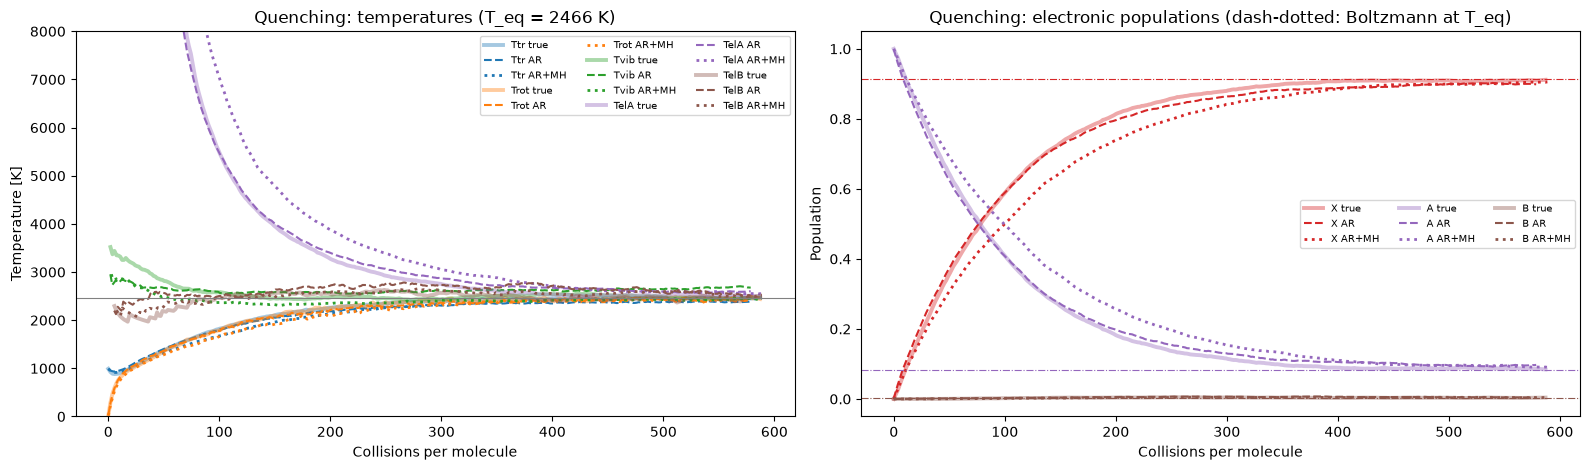

T_eq = 2466 K,  Boltzmann x_el = [0.915  0.0814 0.0036]
  true  : T_tr=2455  T_rot=2457  T_vib(X)=2478  T_el(A)=2517  T_el(B)=2451  x_el=[0.9093 0.0873 0.0034]
  AR    : T_tr=2377  T_rot=2417  T_vib(X)=2657  T_el(A)=2600  T_el(B)=2592  x_el=[0.8982 0.0968 0.0049]
  AR+MH : T_tr=2445  T_rot=2439  T_vib(X)=2430  T_el(A)=2584  T_el(B)=2559  x_el=[0.9004 0.0951 0.0045]
  Energy conservation (rel. drift) AR: 2.2e-14
  Energy conservation (rel. drift) AR+MH: 2.2e-14
1/e relaxation times (energy) in collisions per molecule, Quenching:
  Rotation      true =   68.1   AR =   63.5   AR+MH =   82.8
  Vibration     true =   69.2   AR =   73.3   AR+MH =  106.0
  electronic    true =   96.3   AR =   93.5   AR+MH =  120.7


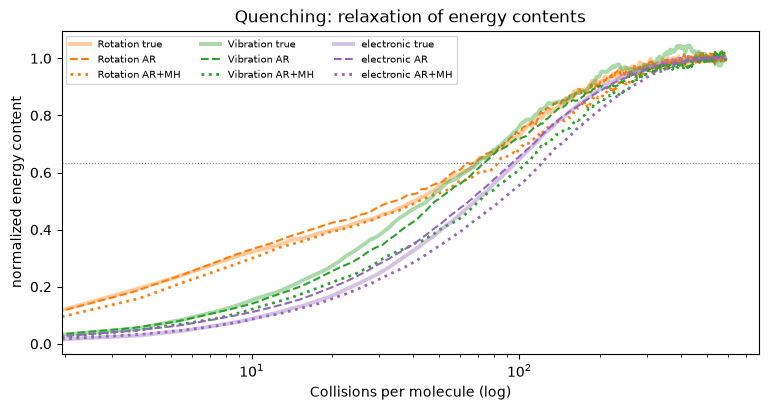

true  : T_el(A) defined from ~39.2 collisions per molecule, there T_el(A) = 32595 K
AR    : T_el(A) defined from ~36.3 collisions per molecule, there T_el(A) = 31506 K
AR+MH : T_el(A) defined from ~46.2 collisions per molecule, there T_el(A) = 33595 K


In [21]:
snaps2 = (5, 25, 80)
runs2, final2 = {}, {}
for name, sampler in [("true", lambda i, e: true_sampler(i, e, rng_true)),
                      ("AR", model_sampler),
                      ("AR+MH", (mh2 := MHSampler()))]:
    t0 = time.time()
    runs2[name], final2[name] = run_heatbath(sampler, 1000.0, idx(1, 0, 0), n_steps=7000, snap_at=snaps2)
    print(f"{name}: {time.time()-t0:.0f}s")
print(mh2.report())
T_eq2 = plot_run(runs2, "Quenching", T_ylim=(0, 8000))
plot_energy_relaxation(runs2, "Quenching")

# When does the population inversion end (x_A/x_X < g_A/g_X), and how hot is T_el(A) then?
for name, r in runs2.items():
    k = np.argmax(np.isfinite(r["TelA"]))
    print(f"{name:6s}: T_el(A) defined from ~{r['t'][k]:.1f} collisions per molecule, there T_el(A) = {r['TelA'][k]:.0f} K")

### Vibrational distribution in the ground state X during quenching

For comparison, the Boltzmann distribution at the *instantaneous* translational temperature is shown. A deviation indicates that vibration is not in equilibrium with translation.

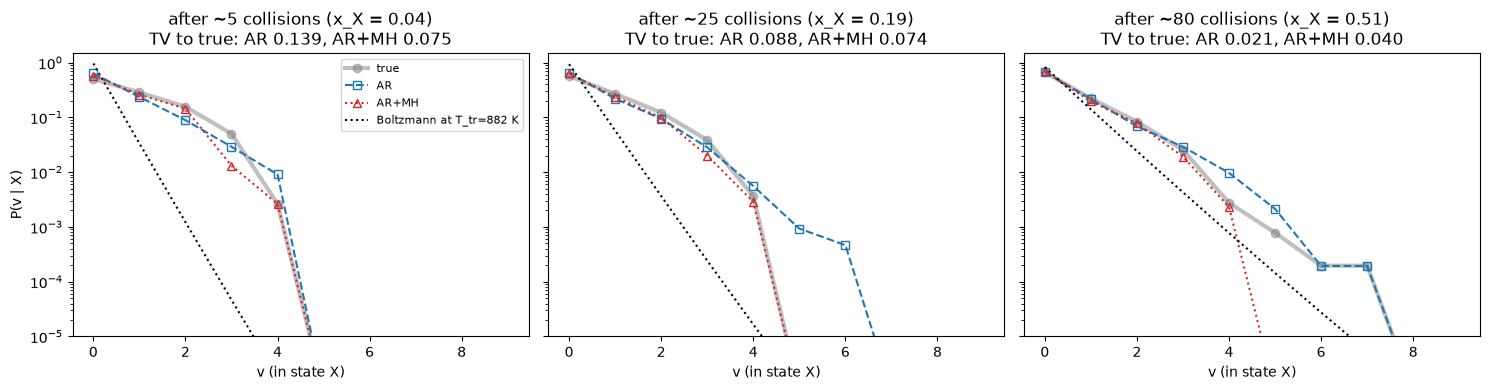

Quench time (1/e) in collisions per molecule:  true = 97.2,  AR = 96.5,  AR+MH = 123.5


In [22]:
fig, ax = plt.subplots(1, len(snaps2), figsize=(5 * len(snaps2), 4), sharey=True)
tv = lambda p, q: 0.5 * np.abs(p - q).sum()
SNAPSTY = {"true": dict(marker="o", color="gray", lw=3, alpha=0.5), "AR": dict(marker="s", color="C0", ls="--", mfc="none"),
           "AR+MH": dict(marker="^", color="C3", ls=":", mfc="none")}
for c, s in enumerate(snaps2):
    k = np.argmin(np.abs(runs2["true"]["t"] - s))
    T_now = runs2["true"]["Ttr"][k]
    p_ref = np.exp(-eps_vib[0] / T_now); p_ref /= p_ref.sum()
    pops = {}
    for name, r in runs2.items():
        st = r["snaps"][s]; stX = st[e_of[st] == 0]
        pops[name] = np.bincount(v_of[stX], minlength=NV) / max(len(stX), 1)
        ax[c].semilogy(v_idx, np.clip(pops[name], 1e-6, None), label=name, **SNAPSTY[name])
    ax[c].semilogy(v_idx, p_ref, "k:", label=f"Boltzmann at T_tr={T_now:.0f} K")
    x_X = np.mean(e_of[runs2["true"]["snaps"][s]] == 0)
    ax[c].set_title(f"after ~{s} collisions (x_X = {x_X:.2f})\nTV to true: AR {tv(pops['AR'], pops['true']):.3f}, "
                    f"AR+MH {tv(pops['AR+MH'], pops['true']):.3f}")
    ax[c].set_xlabel("v (in state X)"); ax[c].set_ylim(1e-5, 1.5)
ax[0].set_ylabel("P(v | X)"); ax[0].legend(fontsize=8)
plt.tight_layout(); plt.show()

# Quench time: when has x_A dropped to 1/e of its excess over equilibrium?
def quench_time(r, xA_eq):
    y = (r["xel"][:, 1] - xA_eq) / (r["xel"][0, 1] - xA_eq)
    k = np.argmax(y < np.exp(-1))
    return np.interp(np.exp(-1), [y[k], y[k-1]], [r["t"][k], r["t"][k-1]])
xA_eq = boltzmann_pops(T_eq2)[0][1]
print("Quench time (1/e) in collisions per molecule:  " +
      ",  ".join(f"{n} = {quench_time(r, xA_eq):.1f}" for n, r in runs2.items()))

**Interpretation**

- **Quench rate:** Whether the AR model gets the time scale right depends on the rare electronic transitions. An error of a few percent in $p_\theta(e' \mid \cdot)$ carries over directly to the quench time. Deviations of a few percent are typical here (see output above).
- **Order of the modes (energy plots):** During heating, rotation relaxes in ~5 collisions, vibration and electronic excitation only after ~70–75. Rotation **overshoots** (normalized energy content up to 1.2): it is initially in equilibrium with the still-hot translation and then cools down together with it, while vibration and electronic modes slowly take up energy. In quenching it is the other way round: translation and rotation are heated only by quenching and therefore follow it on a similar time scale.
- **Metropolis-Hastings (AR+MH):** The **equilibrium** becomes clearly better. During heating, all temperatures and populations match the truth within noise, and the systematic shift of the plain AR model (e.g. $T_\text{vib}(X)$ by +6 %) disappears. The price is the **dynamics**: ~20–25 % of electronic proposals are rejected, and these collisions become elastic. Vibration, electronic excitation and quenching thus become 20–30 % slower (quench time ~126 instead of ~97 collisions). This is the typical trade-off: MH guarantees the thermodynamics exactly but distorts the kinetics, and the more so the worse the network satisfies detailed balance on its own. The remedy is a better $q_\theta$: more data for the rare channels, a penalty term for detailed balance, or training through the MH step (idea 2). Then the acceptance rate approaches 1 and both are correct.
- **E-V transfer:** At the start, the X vibration is clearly **hotter than translation**, because freshly quenched molecules preferentially land in $v = 1\dots3$. This is pure state-to-state information. A model that puts electronic energy wholesale into translation or distributes it thermally cannot capture this.
- **Equilibrium:** The residual population in A ($\sim g_A e^{-T_A/T}$) is sensitive to violations of detailed balance in the $\Delta e \neq 0$ transitions (cf. 6b).

## 9. Ideas for further exploration

1. **Radiative decay:** Add A → X via spontaneous emission, with a probability $1 - e^{-A_{21}\Delta t}$ per time step, independent of collisions. The energy leaves the system (optically thin), and there is *no* detailed balance for this channel. It therefore does not belong in the AR collision model but in DSMC as a separate step. Compare collisional quenching and radiation (Stern-Volmer behavior).
2. **Train through the MH step:** Fit not $q_\theta$ but the effective transition probability $q_\theta \cdot A$ (plus the elastic remainder) to the data. Then both equilibrium **and** dynamics are correct. With 1500 states, the sum over all final states is still feasible.
3. **Weighting rare channels:** Oversample $\Delta e \neq 0$ trajectories in training (corrected via sample weights in `model.fit`) and check whether the quench time becomes more accurate.
4. **Train without uniformly distributed initial states** (`frac_uniform=0`): How well does the network extrapolate in the quenching scenario?
5. **Spin selection rules:** Make X ↔ B "forbidden" ($K_{XB} = 0$). Then B has to relax via A, producing a cascade.
6. **Electron collisions:** Add a second collision partner (electrons) with its own AR model. This is the typical situation in plasmas and during reentry.